# Noise Effects

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import healpy as hp
import os
import camb
from camb import model, initialpower
from scipy.optimize import minimize
from corner import corner
from minkasi.null_test.estimators import polspice
from minkasi import util as mt

pars = camb.CAMBparams()

In [3]:
import pysm3
import pysm3.units as u
nside = 32
npix = hp.nside2npix(nside)

sky = pysm3.Sky(nside=nside, preset_strings=["s0", "d0"], output_unit=u.uK_CMB)

In [4]:
# Convert foregrounds to CMB units
total23 = sky.get_emission(23 * u.GHz)
total93 = sky.get_emission(93 * u.GHz)
total353 = sky.get_emission(353 * u.GHz)

print("ORIGINAL Foreground RMS")
print(f"23 GHz:  {np.std(total23):.2f}")
print(f"93 GHz:  {np.std(total93):.2f}")
print(f"353 GHz: {np.std(total353):.2f}")

print(total23.unit)
print(total93.unit)
print(total353.unit)

total23 = np.array(total23)
total93 = np.array(total93)
total353 = np.array(total353)

ORIGINAL Foreground RMS
23 GHz:  149.63 uK_CMB
93 GHz:  99.07 uK_CMB
353 GHz: 5583.39 uK_CMB
uK_CMB
uK_CMB
uK_CMB


## Function Definitions

In [5]:
lmax=32
def get_Clhat(tau, lmax=lmax, raw_cl=True,
              H0=67, Ombh2=0.024, Omch2=0.12,
              As=2.1e-9, ns=0.965, ks=0.05, 
              kt=0.05, Omk=0, TCMB=2.7255, 
              mnu=0.06, r=0, YHe=0.245400,):
    '''
    Specify tau, and use other known parameters
    '''
    pars.set_cosmology(H0=H0, ombh2=Ombh2, omch2=Omch2, mnu=mnu, omk=Omk, tau=tau, TCMB=TCMB, YHe=YHe)
    pars.InitPower.set_params(As=As, ns=ns, r=r, pivot_scalar=ks, pivot_tensor=kt)
    results = camb.get_results(pars)
    powers = results.get_total_cls(lmax=lmax, CMB_unit='muK', raw_cl=True)
    TT, EE, BB, TE = powers.T
    #ls = np.arange(2, EE.shape[0]) # could add??
    return np.array([TT, EE, BB, TE])

true_tau = 0.054
ls = np.arange(2, lmax+1)
true_spectra = get_Clhat(true_tau) # ensemble average power spectrum
Z = ls*(ls+1)/(2*np.pi)
# plt.semilogx(ls, true_spectra[1][ls]*Z)
# plt.xlabel(r'$\ell$')
# plt.ylabel(r'$\frac{\ell(\ell+1)}{2\pi}C_\ell$\,$\mathrm{[\mu K^2]}$')
# plt.title("True CMB EE Spectrum")


In [6]:
def f(a, maps):
    if len(a) == 1:
        coeffs = np.array([a[0], 1-a[0]])
    else:
        coeffs = np.concatenate((a, [1-sum(a)]))
    chat = coeffs.dot(maps)
    return chat.var()

In [7]:
grid_min = 0.005
grid_max = 0.15
grid_size = 500

tau_coarse_grid = np.linspace(grid_min, grid_max, 100)

EE_coarse_grid = np.array([
    get_Clhat(t)[1]
    for t in tau_coarse_grid
])

from scipy.interpolate import CubicSpline
EE_cubicspline = CubicSpline(
    tau_coarse_grid, 
    EE_coarse_grid, 
    axis=0
)

tau_grid = np.linspace(grid_min, grid_max, grid_size)

EE_grid = EE_cubicspline(tau_grid)

### Currently Unused

In [ ]:
def run_simulation(noise1, noise2, anafast_estimator, nsim):

    # NET = np.array([noise1,noise2])
    # T_per_pix = 365*24*60*60/npix
    # sigma_pix = NET/T_per_pix**0.5


    npix = hp.nside2npix(nside)
    solid_angle = hp.nside2pixarea(nside)
    # map sensitivity
    noise = np.array([noise1, noise2]) #uK arcmin
    sigma_pix = noise * (np.pi / 180 / 60)/ np.sqrt(solid_angle)

    Nl = 4*np.pi * sigma_pix**2 / npix

    auto_tau = []
    cross_tau = []
    auto_ps = []
    cross_ps = []

    theta, phi = hp.pix2ang(nside, np.arange(hp.nside2npix(nside)))
    b = np.pi/2 - theta
    mask_gal = np.abs(b) > np.deg2rad(20)

    mask_class = mt.dec_mask(nside, [-74, 28]) #dec range for CLASS map

    mask = mask_gal

    for i in range(nsim):
        s = hp.synfast(true_spectra, nside, lmax=lmax, new=True)
        nlow1 = np.random.randn(npix) * sigma_pix[0]
        nlow2 = np.random.randn(npix) * sigma_pix[0]
        nhigh1 = np.random.randn(npix) * sigma_pix[1]
        nhigh2 = np.random.randn(npix) * sigma_pix[1]

        combined23_1 = s + total23 + nlow1*np.sqrt(2)
        combined23_2 = s + total23 + nlow2*np.sqrt(2)
        combined23_auto = s + total23 + nlow1
        combined93 = s + total93
        combined353_1 = s + total353 + nhigh1*np.sqrt(2)
        combined353_2 = s + total353 + nhigh2*np.sqrt(2)
        combined353_auto = s + total353 + nhigh1

        chat_1 = np.empty((3, npix))
        chat_1[0] = np.zeros(npix)
        chat_2 = np.empty((3, npix))
        chat_2[0] = np.zeros(npix)
        chat_auto = np.empty((3, npix))
        chat_auto[0] = np.zeros(npix)
        Nl_eff1 = np.zeros(3)
        Nl_eff2 = np.zeros(3)
        Nl_eff3 = np.zeros(3)

        for j in (1,2):
            temp_arr_1 = np.array([combined23_1[j], combined93[j], combined353_1[j]])
            x0 = np.zeros(len(temp_arr_1)-1)
            sol = minimize(f, x0, args=(temp_arr_1))
            a1 = np.concatenate((sol.x, np.array([1-sum(sol.x)])))
            chat_1[j] = a1.dot(temp_arr_1)

            temp_arr_2 = np.array([combined23_2[j], combined93[j], combined353_2[j]])
            x0 = np.zeros(len(temp_arr_2)-1)
            sol = minimize(f, x0, args=(temp_arr_2))
            a2 = np.concatenate((sol.x, np.array([1-sum(sol.x)])))
            chat_2[j] = a2.dot(temp_arr_2)

            temp_arr_auto = np.array([combined23_auto[j], combined93[j], combined353_auto[j]])
            x0 = np.zeros(len(temp_arr_auto)-1)
            sol = minimize(f, x0, args=(temp_arr_auto))
            a3 = np.concatenate((sol.x, np.array([1-sum(sol.x)])))
            chat_auto[j] = a3.dot(temp_arr_auto)

            Nl_eff1[j] = (a1[0]**2*Nl[0] + a1[2]**2*Nl[1])*2
            Nl_eff2[j] = (a2[0]**2*Nl[0] + a2[2]**2*Nl[1])*2
            Nl_eff3[j] = a3[0]**2*Nl[0] + a3[2]**2*Nl[1]

        # ------------------------ANAFAST------------------------
        if anafast_estimator:
            Clhat_auto = hp.anafast(chat_auto, lmax=lmax)[1]
            Clhat_cross = hp.anafast(chat_1, chat_2, lmax=lmax)[1]
        #------------------------POLSPICE------------------------
        else: 
            Clhat_auto = np.array(polspice(m1=chat_auto,weight1=mask,noT=True, pol=True, nlmax=lmax)[1])
            Clhat_cross = np.array(polspice(m1=chat_1, m2=chat_2,weight1=mask, weight2=mask,noT=True, pol=True, nlmax=lmax)[1])
            print('oops')

        Nl_EE1 = 0.5*np.sum(Nl_eff1)
        Nl_EE2 = 0.5*np.sum(Nl_eff2)
        Nl_EE3 = 0.5*np.sum(Nl_eff3)

        var_grid_auto = np.array([
            (2/(2*ls + 1))*((ee[ls] + Nl_EE3)**2)
            for ee in EE_grid
        ])

        var_grid_cross = np.array([
            (1/(2*ls + 1))*(ee[ls]**2 + (ee[ls] + Nl_EE1)*(ee[ls] + Nl_EE2))
            for ee in EE_grid
        ])

        log_var_grid_auto = np.log(2*np.pi*var_grid_auto)
        log_var_grid_cross = np.log(2*np.pi*var_grid_cross)

        chi2_auto = np.sum(
            ((Clhat_auto[None, 2:33] - EE_grid[:, 2:33])**2 / var_grid_auto) + log_var_grid_auto,
            axis=1
        )

        chi2_cross = np.sum(
            ((Clhat_cross[None, 2:33] - EE_grid[:, 2:33])**2 / var_grid_cross) + log_var_grid_cross,
            axis=1
        )

        auto_tau.append(tau_grid[np.argmin(chi2_auto)])
        cross_tau.append(tau_grid[np.argmin(chi2_cross)])
        auto_ps.append(Clhat_auto)
        cross_ps.append(Clhat_cross)

    print('done')
    return np.array(auto_tau), np.array(cross_tau), np.array(auto_ps), np.array(cross_ps)

In [35]:
# no noise
def run_simulation_noiseless(anafast_estimator, nsim):

    tau = []
    ps = []

    theta, phi = hp.pix2ang(nside, np.arange(hp.nside2npix(nside)))
    b = np.pi/2 - theta
    mask_gal = np.abs(b) > np.deg2rad(20)

    mask_class = mt.dec_mask(nside, [-74, 28]) #dec range for CLASS map

    mask = mask_gal

    for i in range(nsim):
        s = hp.synfast(true_spectra, nside, lmax=lmax, new=True)

        combined23 = s + total23
        combined93 = s + total93
        combined353 = s + total353

        chat = np.empty((3, npix))
        chat[0] = np.zeros(npix)


        for j in (1,2):
            temp_arr_1 = np.array([combined23[j], combined93[j], combined353[j]])
            x0 = np.zeros(len(temp_arr_1)-1)
            sol = minimize(f, x0, args=(temp_arr_1))
            a1 = np.concatenate((sol.x, np.array([1-sum(sol.x)])))
            chat[j] = a1.dot(temp_arr_1)

        # ------------------------ANAFAST------------------------
        if anafast_estimator:
            Clhat = hp.anafast(chat, lmax=lmax)[1]
        #------------------------POLSPICE------------------------
        else: 
            Clhat = np.array(polspice(m1=chat,weight1=mask,noT=True, pol=True, nlmax=lmax)[1])
            print('oops')

        var_grid = np.array([
            (2/(2*ls + 1))*((ee[ls])**2)
            for ee in EE_grid
        ])

        log_var_grid = np.log(2*np.pi*var_grid)

        chi2 = np.sum(
            ((Clhat[None, 2:33] - EE_grid[:, 2:33])**2 / var_grid) + log_var_grid,
            axis=1
        )

        tau.append(tau_grid[np.argmin(chi2)])
        ps.append(Clhat)

    print('done')
    return np.array(tau), np.array(ps)

In [56]:
def sigma_tau_plot():
    sigma_tau = []
    bias_tau = []

    for n in noises:
        auto = no_foreground_sim(n,False,250)
        sigma_tau.append(auto.std())
        bias_tau.append(auto.mean() - 0.054)
        print(n)

    return np.array(sigma_tau), np.array(bias_tau)


## reproducing sigma tau plot: adding wishart

In [4]:
theta, phi = hp.pix2ang(nside, np.arange(hp.nside2npix(nside)))
b = np.pi/2 - theta
mask_gal = np.abs(b) > np.deg2rad(15)

mask_class = mt.dec_mask(nside, [-74, 28], coord='G') #dec range for CLASS map

mask = mask_class & mask_gal

print(np.mean(mask))

0.5397135416666666


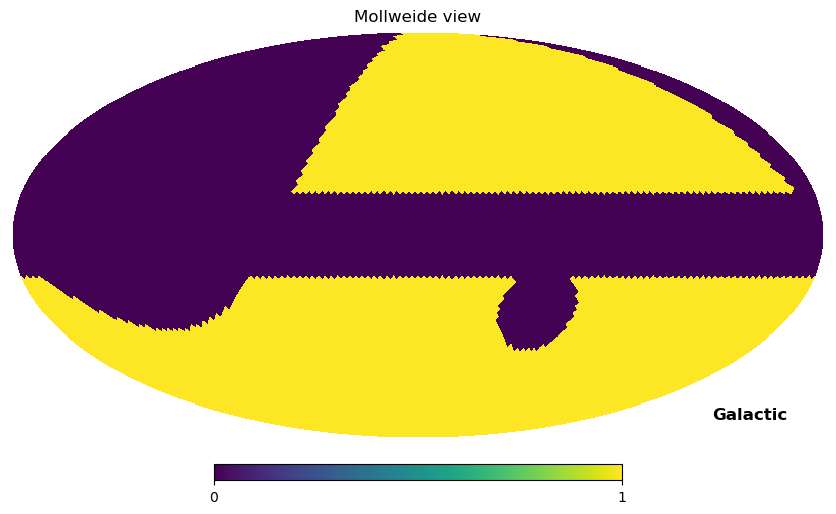

In [5]:
hp.mollview(mask,coord="G")

In [59]:
## testing with anafast
def no_foreground_sim(noise, class_mask, nsim):
    tau_auto = []
    #tau_cross = []
    
    # NOISE CALCS
    npix = hp.nside2npix(nside)
    solid_angle = hp.nside2pixarea(nside)
    # map sensitivity
    sigma_pix = noise * (np.pi / 180 / 60)/ np.sqrt(solid_angle)
    
    Nl = 4*np.pi * sigma_pix**2 / npix

    # MASKS
    theta, phi = hp.pix2ang(nside, np.arange(hp.nside2npix(nside)))
    b = np.pi/2 - theta
    mask_gal = np.abs(b) > np.deg2rad(20)

    mask_class = mt.dec_mask(nside, [-74, 28], coord='G') #dec range for CLASS map

    if class_mask:
        mask = mask_class & mask_gal
    else:
        mask = mask_gal

    fsky = np.mean(mask)

    # VARIANCES
    var_grid_auto = np.array([
        ((2/(2*ls + 1))*(ee[ls] + Nl)**2)#/fsky
        for ee in EE_grid
    ])

    # var_grid_cross = np.array([
    #     (1/(2*ls + 1))*(2*(ee[ls]**2) + 4*(Nl)**2 + (4*ee[ls]*Nl))/fsky
    #     for ee in EE_grid
    # ])

    log_var_auto = np.log(2*np.pi*var_grid_auto)
    #log_var_cross = np.log(2*np.pi*var_grid_cross)

    for i in range(nsim):
        s = hp.synfast(true_spectra, nside, lmax=lmax, new=True, pol=True)

        n1 = np.random.randn(npix) * sigma_pix 
        n2 = np.random.randn(npix) * sigma_pix

        m1 = s + n1 * np.sqrt(2)
        m2 = s + n2 * np.sqrt(2)
        m_auto = s + n1

        Clhat_auto = np.array(polspice(m1=m_auto,weight1=mask,noT=True, pol=True, nlmax=lmax)[1])
        #Clhat_auto = np.array(polspice(m1=m_auto,noT=True, pol=True, nlmax=lmax)[1])
        #Clhat_auto = hp.anafast(m_auto, lmax=lmax)[1]
        # Clhat_cross = np.array(polspice(m1=m1, m2=m2,weight1=mask,weight2=mask,noT=True, pol=True, nlmax=lmax, apodizesigma=120.0)[1])

        # chi2_cross = np.sum(
        #     ((Clhat_cross[None, 2:33] - EE_grid[:, 2:33])**2 / var_grid_cross) + log_var_cross,
        #     axis=1
        # )

        # chi2_auto = np.sum(
        #     ((Clhat_auto[None, 2:33] - (Nl) - EE_grid[:, 2:33])**2 / var_grid_auto) + log_var_auto,
        #     axis=1
        # )

        x = ((Clhat_auto[ls][None, :])/(EE_grid[:, ls]+ Nl))

        chi2_auto = np.sum(
            (2*ls+1)*(x - np.log(x) - 1),
            axis=1
        )

        # tau_cross.append(tau_grid[np.argmin(chi2_cross)])
        tau_auto.append(tau_grid[np.argmin(chi2_auto)])
    return np.array(tau_auto)#, np.array(tau_cross)
    


In [17]:
def foreground_baseline(noise, nsim):
    npix = hp.nside2npix(nside)
    solid_angle = hp.nside2pixarea(nside)
    # map sensitivity
    sigma_pix = noise * (np.pi / 180 / 60)/ np.sqrt(solid_angle)

    Nl = 4*np.pi * sigma_pix**2 / npix

    auto_tau = []

    for i in range(nsim):
        s = hp.synfast(true_spectra, nside, lmax=lmax, new=True)
        n = np.zeros((3, npix))
        n[1] = np.random.randn(npix) * sigma_pix   # Q
        n[2] = np.random.randn(npix) * sigma_pix   # U

        combined23 = s + total23
        combined93 = s + total93 + n
        combined353 = s + total353

        chat_auto = np.empty((3, npix))
        chat_auto[0] = np.zeros(npix)
        Nl_eff = np.zeros(3)


        for j in (1,2):
            temp_arr_auto = np.array([combined23[j], combined93[j], combined353[j]])
            x0 = np.zeros(len(temp_arr_auto)-1)
            sol = minimize(f, x0, args=(temp_arr_auto))
            a = np.concatenate((sol.x, np.array([1-sum(sol.x)])))
            chat_auto[j] = a.dot(temp_arr_auto)

            Nl_eff[j] = a[1]**2*Nl

        
        Clhat_auto = np.array(polspice(m1=chat_auto,noT=True, pol=True, nlmax=lmax)[1])

        Nl_EE = 0.5*np.sum(Nl_eff)

        x = ((Clhat_auto[ls][None, :])/(EE_grid[:, ls]+ Nl_EE))

        chi2_auto = np.sum(
            (2*ls+1)*(x - np.log(x) - 1),
            axis=1
        )

        auto_tau.append(tau_grid[np.argmin(chi2_auto)])
        #auto_ps.append(Clhat_auto)

    return np.array(auto_tau)

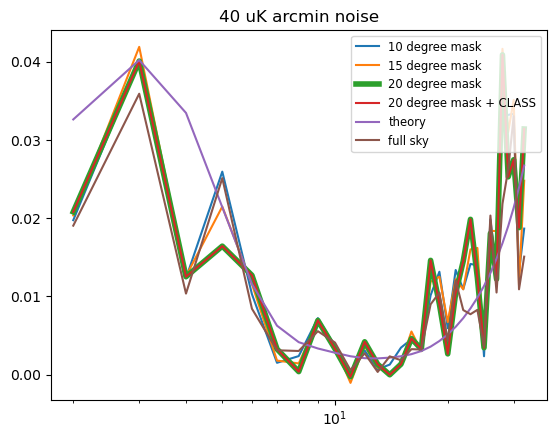

In [95]:
#Clhat = no_foreground_sim(20, False)
npix = hp.nside2npix(nside)
solid_angle = hp.nside2pixarea(nside)
# map sensitivity
sigma_pix = 40 * (np.pi / 180 / 60)/ np.sqrt(solid_angle)

Nl = 4*np.pi * sigma_pix**2 / npix

# MASKS
theta, phi = hp.pix2ang(nside, np.arange(hp.nside2npix(nside)))
b = np.pi/2 - theta
mask_gal = np.abs(b) > np.deg2rad(10)

s = hp.synfast(true_spectra, nside, lmax=lmax, new=True, pol=True)
n1 = np.random.randn(npix) * sigma_pix 
m_auto = s + n1

plt.semilogx(ls, (np.array(polspice(m1=m_auto,weight1=mask_gal,noT=True, pol=True, nlmax=lmax)[1][ls])-Nl)*Z, label='10 degree mask')
mask_gal = np.abs(b) > np.deg2rad(15)
plt.semilogx(ls, (np.array(polspice(m1=m_auto,weight1=mask_gal,noT=True, pol=True, nlmax=lmax)[1][ls])-Nl)*Z,  label='15 degree mask')
mask_gal = np.abs(b) > np.deg2rad(20)
plt.semilogx(ls, (np.array(polspice(m1=m_auto,weight1=mask_gal,noT=True, pol=True, nlmax=lmax)[1][ls])-Nl)*Z, label='20 degree mask', lw=4)
mask_class = mt.dec_mask(nside, [-74, 28], coord='G')
mask = mask_class & mask_gal
plt.semilogx(ls, (np.array(polspice(m1=m_auto,weight1=mask_gal,noT=True, pol=True, nlmax=lmax)[1][ls])-Nl)*Z, label='20 degree mask + CLASS')
plt.semilogx(ls, true_spectra[1][ls]*Z, label='theory')
plt.semilogx(ls, (hp.anafast(m_auto, lmax=lmax)[1][ls]-Nl)*Z, label='full sky')
plt.title("40 uK arcmin noise")
plt.legend(fontsize='small', loc='upper right')

In [25]:
def get_simulation_stats(auto_tau, cross_tau, Clhat_auto, Clhat_cross):
    #taus = np.array([auto_tau, cross_tau])
    #ps = np.array([Clhat_auto, Clhat_cross])

    bias_auto = np.mean(auto_tau) - 0.054
    err_auto = np.std(auto_tau)
    bias_cross = np.mean(cross_tau) - 0.054
    err_cross = np.std(cross_tau)

    mean_auto = np.mean(Clhat_auto, axis=0)[None, 2:33]
    mean_cross = np.mean(Clhat_cross, axis=0)[None, 2:33]
    std_auto = np.std(Clhat_auto, axis=0)[None, 2:33]
    std_cross = np.std(Clhat_cross, axis=0)[None, 2:33]

    return bias_auto, err_auto, np.array([mean_auto, std_auto]), np.array([mean_cross, std_cross]), bias_cross, err_cross


In [53]:
print(np.arange(0,205,5))
# MASKS
theta, phi = hp.pix2ang(nside, np.arange(hp.nside2npix(nside)))
b = np.pi/2 - theta
mask_gal = np.abs(b) > np.deg2rad(10)

mask_class = mt.dec_mask(nside, [-74, 28]) #dec range for CLASS map


mask = mask_class & mask_gal
print(np.mean(mask))

[  0   5  10  15  20  25  30  35  40  45  50  55  60  65  70  75  80  85
  90  95 100 105 110 115 120 125 130 135 140 145 150 155 160 165 170 175
 180 185 190 195 200]
0.5393880208333334


In [22]:
auto = foreground_baseline(200,100)

In [21]:
print(auto)

[0.05267535 0.06088176 0.0495491  0.05267535 0.04485972 0.05814629
 0.05111222 0.05619238 0.04993988 0.06205411 0.06478958 0.05423848
 0.05111222 0.05541082 0.05697395 0.04446894 0.04720441 0.05658317
 0.05306613 0.06400802 0.04720441 0.0558016  0.0601002  0.04837675
 0.05697395 0.05541082 0.05697395 0.04759519 0.05462926 0.04329659
 0.05267535 0.05892786 0.05228457 0.04915832 0.05228457 0.0601002
 0.05267535 0.05502004 0.0538477  0.0601002  0.05931864 0.05697395
 0.05970942 0.04837675 0.05502004 0.05306613 0.0495491  0.04876754
 0.05306613 0.05619238 0.05541082 0.05111222 0.05072144 0.05502004
 0.04993988 0.05502004 0.05697395 0.05697395 0.05931864 0.05228457
 0.05892786 0.0495491  0.04720441 0.05736473 0.04993988 0.05462926
 0.04485972 0.05619238 0.06283567 0.04798597 0.04407816 0.06088176
 0.05462926 0.06049098 0.05853707 0.05853707 0.04837675 0.04993988
 0.04915832 0.05306613 0.05423848 0.05228457 0.05775551 0.05150301
 0.05892786 0.05462926 0.06166333 0.05345691 0.05931864 0.05267

(array([ 3.,  2.,  5., 19., 28., 26., 12.,  3.,  1.,  1.]),
 array([0.04056112, 0.04571944, 0.05087776, 0.05603607, 0.06119439,
        0.06635271, 0.07151102, 0.07666934, 0.08182766, 0.08698597,
        0.09214429]),
 <BarContainer object of 10 artists>)

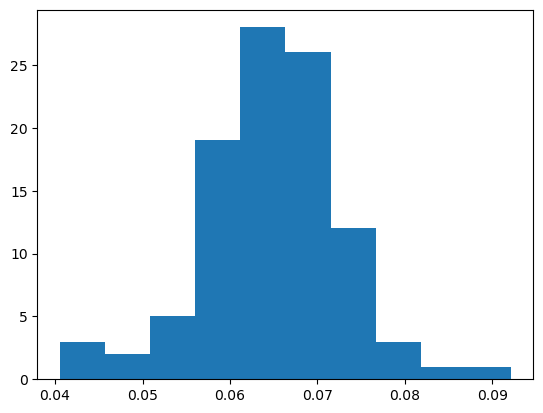

In [23]:
plt.hist(auto)

In [24]:
print(f"{'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{np.std(auto):>12.6f} {np.mean(auto):>12.6f}")

         Std         Mean
------------------------------------------------------
    0.007967     0.064852


In [50]:
noises = np.arange(0,210,10)
sigma, bias = sigma_tau_plot()

0
10
20
30
40
50
60
70
80
90
100
110
120
130
140
150
160
170
180
190
200


In [51]:
print(sigma)

[0.002111   0.00215335 0.00263281 0.00262173 0.0031401  0.00371349
 0.00365992 0.00431343 0.00439801 0.0040372  0.00485447 0.00508043
 0.00557454 0.00542709 0.00613104 0.00699895 0.00677116 0.00715337
 0.00716981 0.00738506 0.00766812]


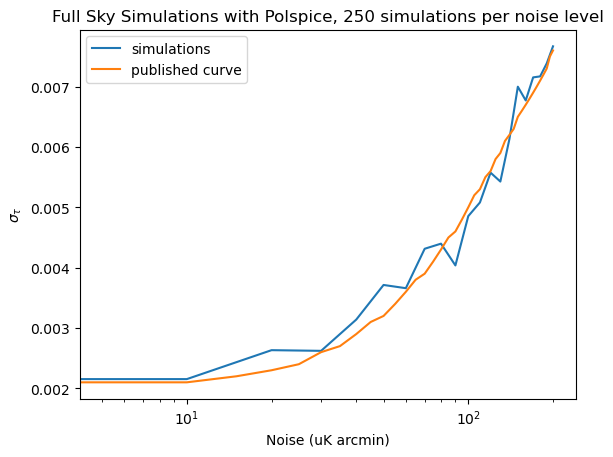

In [53]:
plt.semilogx(noises, sigma, label='simulations')
plt.semilogx(goal['noise'], goal['sigma_tau'], label='published curve')
plt.xlabel("Noise (uK arcmin)")
plt.ylabel(r'$\sigma_{\tau}$')
plt.title("Full Sky Simulations with Polspice, 250 simulations per noise level")
plt.legend()

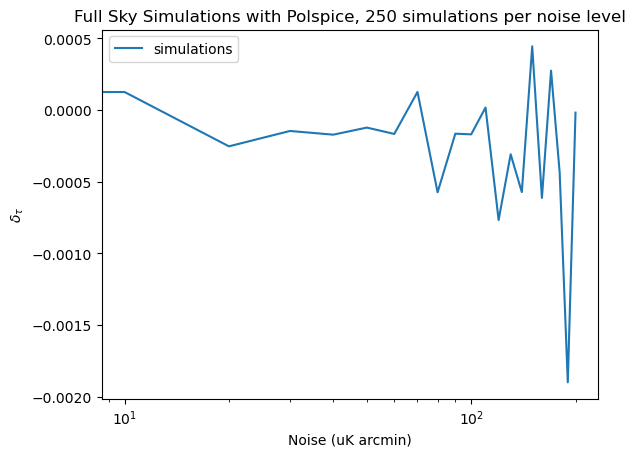

In [54]:
plt.semilogx(noises, bias, label='simulations')
#plt.semilogx(goal['noise'], goal['sigma_tau'], label='published curve')
plt.xlabel("Noise (uK arcmin)")
plt.ylabel(r'$\delta_{\tau}$')
plt.title("Full Sky Simulations with Polspice, 250 simulations per noise level")
plt.legend()

### Simulation output

In [58]:
# noises = np.arange(0,210,10)
# class_mask_auto = sigma_tau_plot()

In [68]:
noises = np.arange(0,210,10)
gal_mask_auto = sigma_tau_plot()

/tmp/ipykernel_3971731/1151801575.py:70: RuntimeWarning: invalid value encountered in log
  (2*ls+1)*(x - np.log(x) - 1),


0
10
20
30
40
50
60
70
80
90
100
110
120
130
140
150
160
170
180
190
200


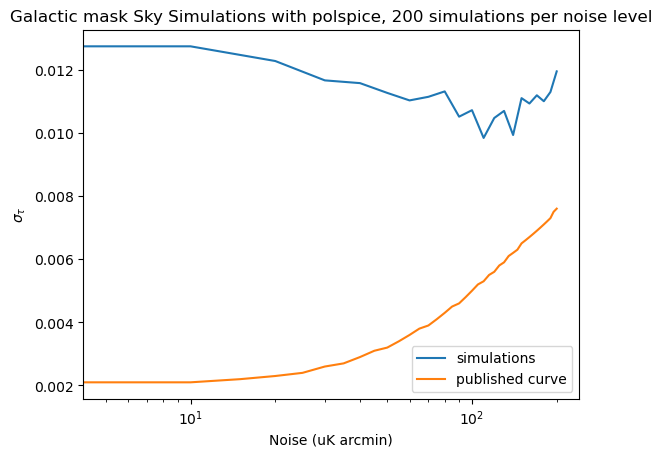

In [63]:
plt.semilogx(noises, gal_mask_auto[0], label='simulations')
plt.semilogx(goal['noise'], goal['sigma_tau'], label='published curve')
plt.xlabel("Noise (uK arcmin)")
plt.ylabel(r'$\sigma_{\tau}$')
plt.title("Galactic mask Sky Simulations with polspice, 200 simulations per noise level")
plt.legend()

In [35]:
noises = np.arange(0,210,10)
full_sky_auto = sigma_tau_plot()

0
10
20
30
40
50
60
70
80
90
100
110
120
130
140
150
160
170
180
190
200


### Plots

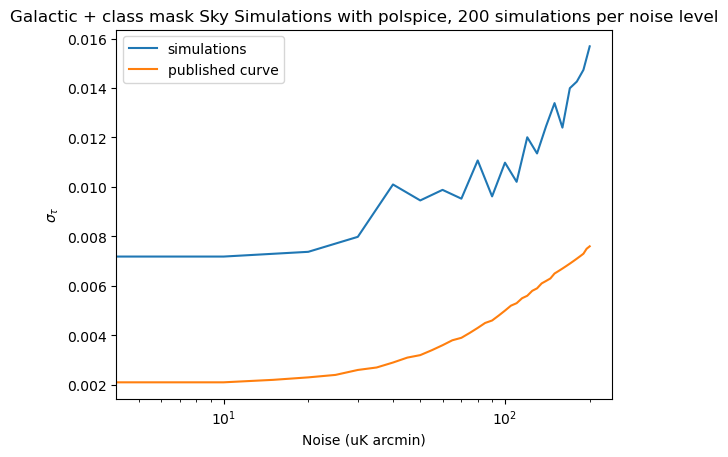

In [90]:
plt.semilogx(noises, class_mask_auto, label='simulations')
plt.semilogx(goal['noise'], goal['sigma_tau'], label='published curve')
plt.xlabel("Noise (uK arcmin)")
plt.ylabel(r'$\sigma_{\tau}$')
plt.title("Galactic + class mask Sky Simulations with polspice, 200 simulations per noise level")
plt.legend()

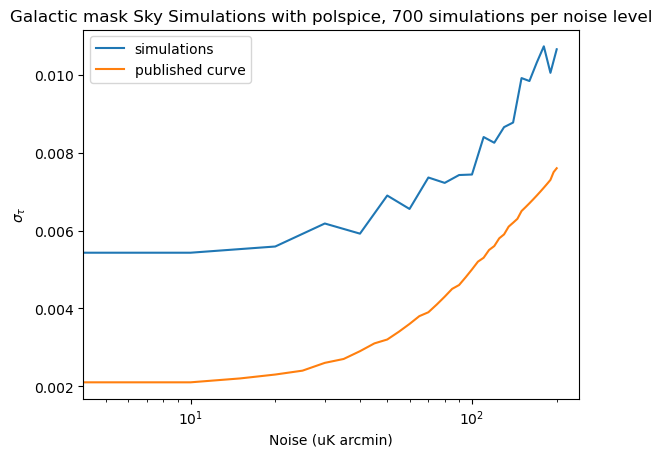

In [68]:
plt.semilogx(noises, gal_mask_auto, label='simulations')
plt.semilogx(goal['noise'], goal['sigma_tau'], label='published curve')
plt.xlabel("Noise (uK arcmin)")
plt.ylabel(r'$\sigma_{\tau}$')
plt.title("Galactic mask Sky Simulations with polspice, 700 simulations per noise level")
plt.legend()

In [16]:
import pandas as pd
goal = pd.read_csv("goal_table.csv", names=['noise','sigma_tau'])

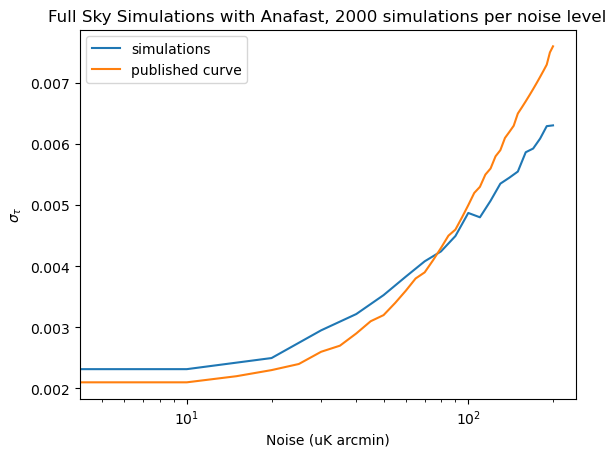

In [67]:
plt.semilogx(noises, full_sky_auto, label='simulations')
plt.semilogx(goal['noise'], goal['sigma_tau'], label='published curve')
plt.xlabel("Noise (uK arcmin)")
plt.ylabel(r'$\sigma_{\tau}$')
plt.title("Full Sky Simulations with Anafast, 2000 simulations per noise level")
plt.legend()

In [43]:
auto = no_foreground_sim(20,False, 100)
#auto_class, cross_class = no_foreground_sim(20,True, 100)


Type                                  Std         Mean
------------------------------------------------------
Auto Spectrum                    0.005643     0.058430


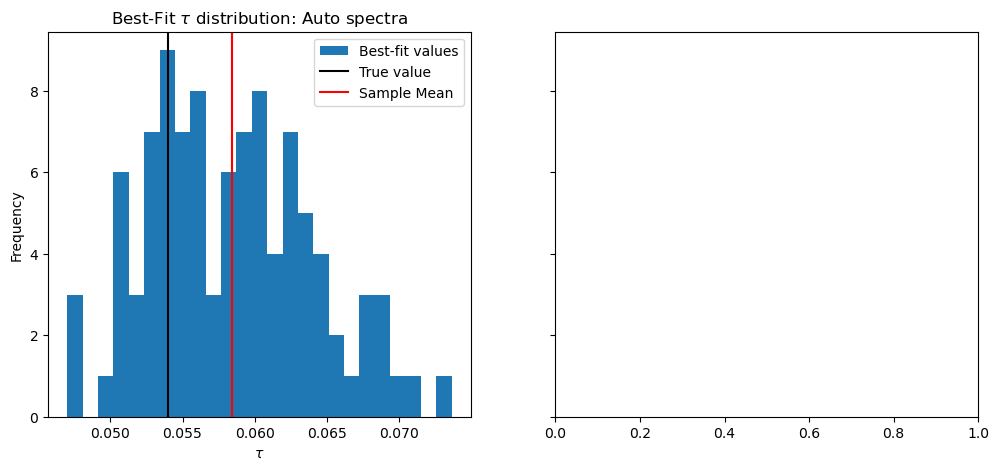

In [44]:
print(f"{'Type':<28} {'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{'Auto Spectrum':<28} {auto.std():>12.6f} {auto.mean():>12.6f}")
#print(f"{'Cross Spectrum':<28} {cross.std():>12.6f} {auto.mean():>12.6f}")

fig, ax = plt.subplots(1,2, figsize=(12,5), sharey=True)

ax[0].hist(auto, bins=25, density=False, label="Best-fit values")
ax[0].set_xlabel(r'$\tau$')
ax[0].set_ylabel("Frequency")
ax[0].set_title("Best-Fit "r'$\tau$' " distribution: Auto spectra")
ax[0].axvline(0.054, color='black', label="True value")
ax[0].axvline(auto.mean(), color='red', label="Sample Mean")
ax[0].legend(loc='best')

# ax[1].hist(cross, bins=25, density=False, label="Best-fit values")
# ax[1].set_xlabel(r'$\tau$')
# ax[1].set_title("Best-Fit "r'$\tau$' " distribution: Cross spectra")
# ax[1].axvline(0.054, color='black', label="True value")
# ax[1].axvline(cross.mean(), color='red', label="Sample Mean")
# ax[1].legend(loc='best')

Type                                  Std         Mean
------------------------------------------------------
Auto Spectrum                    0.006593     0.057857
Cross Spectrum                   0.006577     0.057857


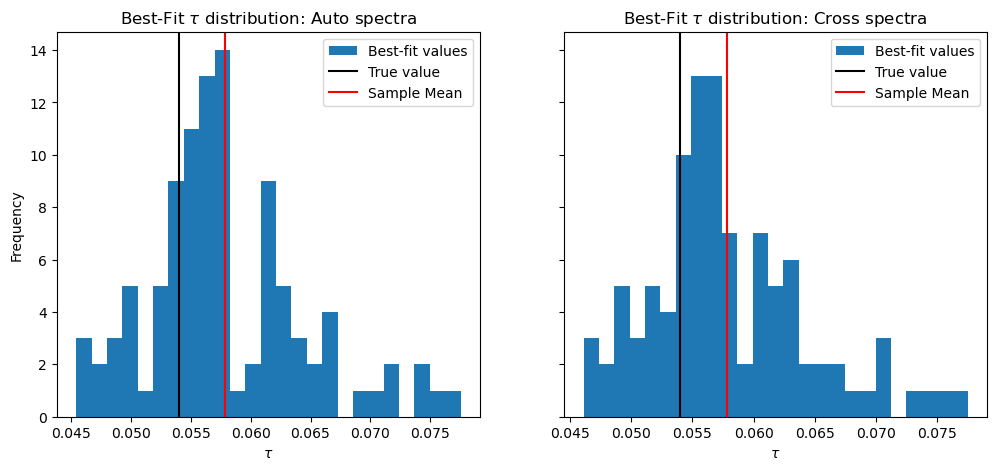

In [59]:
auto = auto_class
cross = cross_class
print(f"{'Type':<28} {'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{'Auto Spectrum':<28} {auto.std():>12.6f} {auto.mean():>12.6f}")
print(f"{'Cross Spectrum':<28} {cross.std():>12.6f} {auto.mean():>12.6f}")

fig, ax = plt.subplots(1,2, figsize=(12,5), sharey=True)

ax[0].hist(auto, bins=25, density=False, label="Best-fit values")
ax[0].set_xlabel(r'$\tau$')
ax[0].set_ylabel("Frequency")
ax[0].set_title("Best-Fit "r'$\tau$' " distribution: Auto spectra")
ax[0].axvline(0.054, color='black', label="True value")
ax[0].axvline(auto.mean(), color='red', label="Sample Mean")
ax[0].legend(loc='best')

ax[1].hist(cross, bins=25, density=False, label="Best-fit values")
ax[1].set_xlabel(r'$\tau$')
ax[1].set_title("Best-Fit "r'$\tau$' " distribution: Cross spectra")
ax[1].axvline(0.054, color='black', label="True value")
ax[1].axvline(cross.mean(), color='red', label="Sample Mean")
ax[1].legend(loc='best')

## Noise Testing

done
         Std         Mean
------------------------------------------------------
    0.002700     0.055230


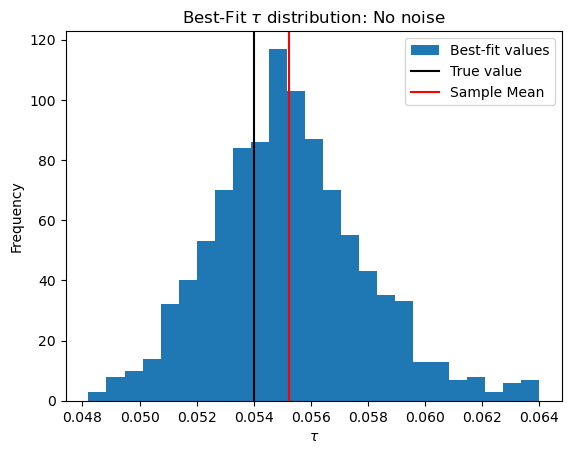

In [37]:
noise_0 = run_simulation_noiseless(True, 1000)
print(f"{'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{noise_0[0].std():>12.6f} {noise_0[0].mean():>12.6f}")

plt.hist(noise_0[0], bins=25, density=False, label="Best-fit values")
plt.xlabel(r'$\tau$')
plt.ylabel("Frequency")
plt.title("Best-Fit "r'$\tau$' " distribution: No noise")
plt.axvline(0.054, color='black', label="True value")
plt.axvline(noise_0[0].mean(), color='red', label="Sample Mean")
plt.legend(loc='best')

done
Type                                  Std         Mean
------------------------------------------------------
Auto Spectrum                    0.002924     0.055176
Cross Spectrum                   0.002922     0.055176


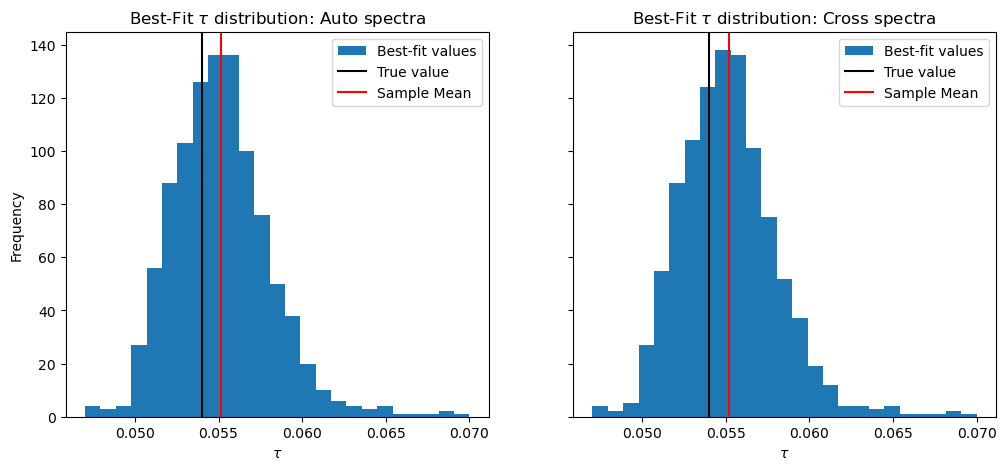

In [21]:
noise_10 = run_simulation(10,10,True, 1000)

auto = noise_10[0]
cross = noise_10[1]
print(f"{'Type':<28} {'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{'Auto Spectrum':<28} {auto.std():>12.6f} {auto.mean():>12.6f}")
print(f"{'Cross Spectrum':<28} {cross.std():>12.6f} {auto.mean():>12.6f}")

fig, ax = plt.subplots(1,2, figsize=(12,5), sharey=True)

ax[0].hist(auto, bins=25, density=False, label="Best-fit values")
ax[0].set_xlabel(r'$\tau$')
ax[0].set_ylabel("Frequency")
ax[0].set_title("Best-Fit "r'$\tau$' " distribution: Auto spectra")
ax[0].axvline(0.054, color='black', label="True value")
ax[0].axvline(auto.mean(), color='red', label="Sample Mean")
ax[0].legend(loc='best')

ax[1].hist(cross, bins=25, density=False, label="Best-fit values")
ax[1].set_xlabel(r'$\tau$')
ax[1].set_title("Best-Fit "r'$\tau$' " distribution: Cross spectra")
ax[1].axvline(0.054, color='black', label="True value")
ax[1].axvline(cross.mean(), color='red', label="Sample Mean")
ax[1].legend(loc='best')

In [26]:
noise_10_stats = get_simulation_stats(noise_10[0], noise_10[1], noise_10[2], noise_10[3])

done
Type                                  Std         Mean
------------------------------------------------------
Auto Spectrum                    0.002685     0.055194
Cross Spectrum                   0.002678     0.055194


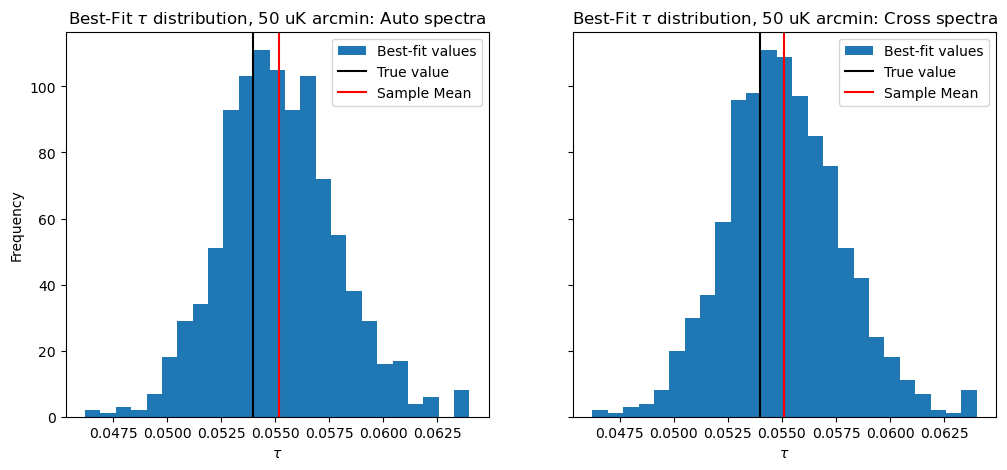

In [38]:
noise_50 = run_simulation(50,50,True, 1000)
noise_50_stats = get_simulation_stats(noise_50[0], noise_50[1], noise_50[2], noise_50[3])

auto = noise_50[0]
cross = noise_50[1]
print(f"{'Type':<28} {'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{'Auto Spectrum':<28} {auto.std():>12.6f} {auto.mean():>12.6f}")
print(f"{'Cross Spectrum':<28} {cross.std():>12.6f} {auto.mean():>12.6f}")

fig, ax = plt.subplots(1,2, figsize=(12,5), sharey=True)

ax[0].hist(auto, bins=25, density=False, label="Best-fit values")
ax[0].set_xlabel(r'$\tau$')
ax[0].set_ylabel("Frequency")
ax[0].set_title("Best-Fit "r'$\tau$' " distribution, 50 uK arcmin: Auto spectra")
ax[0].axvline(0.054, color='black', label="True value")
ax[0].axvline(auto.mean(), color='red', label="Sample Mean")
ax[0].legend(loc='best')

ax[1].hist(cross, bins=25, density=False, label="Best-fit values")
ax[1].set_xlabel(r'$\tau$')
ax[1].set_title("Best-Fit "r'$\tau$' " distribution, 50 uK arcmin: Cross spectra")
ax[1].axvline(0.054, color='black', label="True value")
ax[1].axvline(cross.mean(), color='red', label="Sample Mean")
ax[1].legend(loc='best')

In [ ]:
noise_100 = run_simulation(100,100,True, 1000)
noise_100_stats = get_simulation_stats(noise_100[0], noise_100[1], noise_100[2], noise_100[3])

Type                                  Std         Mean
------------------------------------------------------
Auto Spectrum                    0.003055     0.055826
Cross Spectrum                   0.003028     0.055826


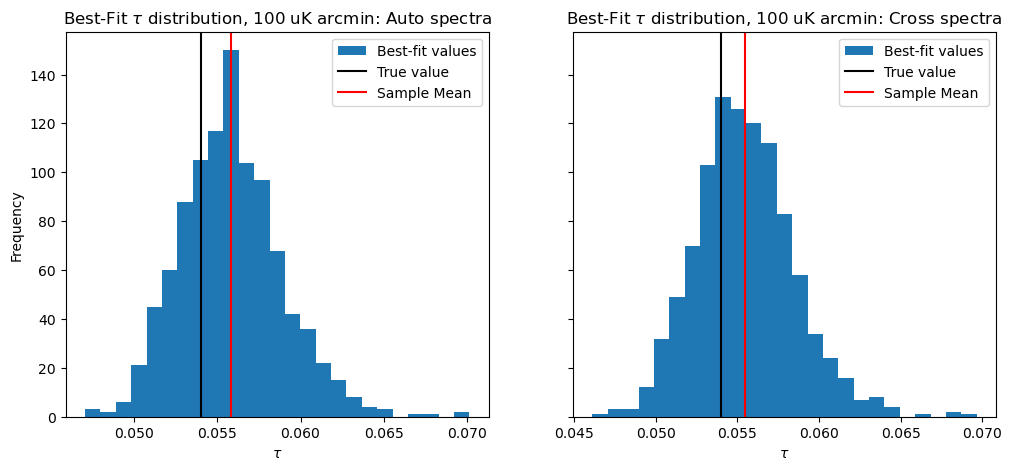

In [68]:
auto = noise_100[0]
cross = noise_100[1]
print(f"{'Type':<28} {'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{'Auto Spectrum':<28} {auto.std():>12.6f} {auto.mean():>12.6f}")
print(f"{'Cross Spectrum':<28} {cross.std():>12.6f} {auto.mean():>12.6f}")

fig, ax = plt.subplots(1,2, figsize=(12,5), sharey=True)

ax[0].hist(auto, bins=25, density=False, label="Best-fit values")
ax[0].set_xlabel(r'$\tau$')
ax[0].set_ylabel("Frequency")
ax[0].set_title("Best-Fit "r'$\tau$' " distribution, 100 uK arcmin: Auto spectra")
ax[0].axvline(0.054, color='black', label="True value")
ax[0].axvline(auto.mean(), color='red', label="Sample Mean")
ax[0].legend(loc='best')

ax[1].hist(cross, bins=25, density=False, label="Best-fit values")
ax[1].set_xlabel(r'$\tau$')
ax[1].set_title("Best-Fit "r'$\tau$' " distribution, 100 uK arcmin: Cross spectra")
ax[1].axvline(0.054, color='black', label="True value")
ax[1].axvline(cross.mean(), color='red', label="Sample Mean")
ax[1].legend(loc='best')

In [ ]:
noise_200 = run_simulation(200,200,True, 1000)
noise_200_stats = get_simulation_stats(noise_200[0], noise_200[1], noise_200[2], noise_200[3])

Type                                  Std         Mean
------------------------------------------------------
Auto Spectrum                    0.003393     0.057059
Cross Spectrum                   0.003784     0.057059


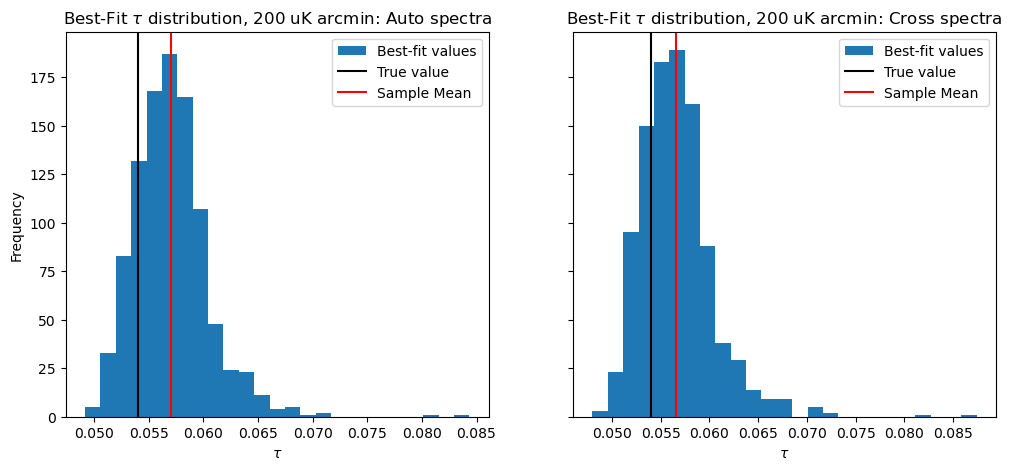

In [66]:
auto = noise_200[0]
cross = noise_200[1]
print(f"{'Type':<28} {'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{'Auto Spectrum':<28} {auto.std():>12.6f} {auto.mean():>12.6f}")
print(f"{'Cross Spectrum':<28} {cross.std():>12.6f} {auto.mean():>12.6f}")

fig, ax = plt.subplots(1,2, figsize=(12,5), sharey=True)

ax[0].hist(auto, bins=25, density=False, label="Best-fit values")
ax[0].set_xlabel(r'$\tau$')
ax[0].set_ylabel("Frequency")
ax[0].set_title("Best-Fit "r'$\tau$' " distribution, 200 uK arcmin: Auto spectra")
ax[0].axvline(0.054, color='black', label="True value")
ax[0].axvline(auto.mean(), color='red', label="Sample Mean")
ax[0].legend(loc='best')

ax[1].hist(cross, bins=25, density=False, label="Best-fit values")
ax[1].set_xlabel(r'$\tau$')
ax[1].set_title("Best-Fit "r'$\tau$' " distribution, 200 uK arcmin: Cross spectra")
ax[1].axvline(0.054, color='black', label="True value")
ax[1].axvline(cross.mean(), color='red', label="Sample Mean")
ax[1].legend(loc='best')

done
Type                                  Std         Mean
------------------------------------------------------
Auto Spectrum                    0.004748     0.060664
Cross Spectrum                   0.006124     0.060664


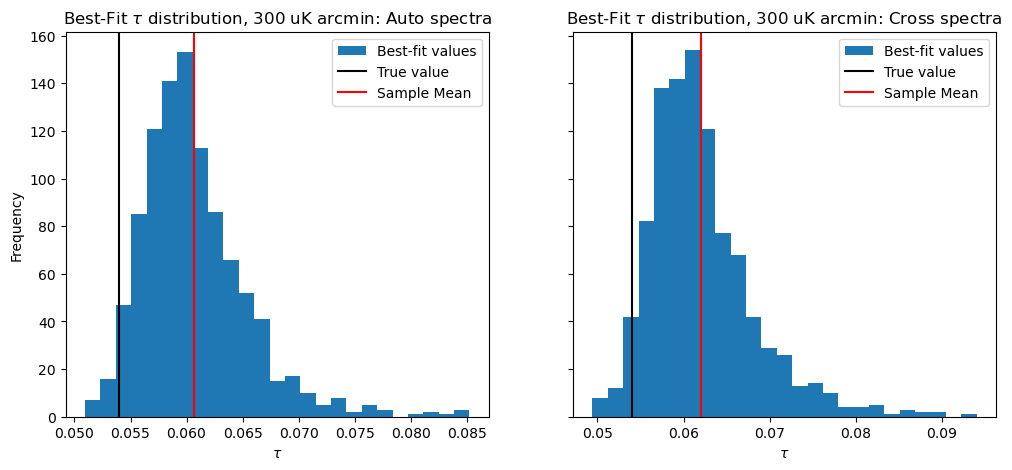

In [58]:
noise_300 = run_simulation(300,300,True, 1000)
noise_300_stats = get_simulation_stats(noise_300[0], noise_300[1], noise_300[2], noise_300[3])

auto = noise_300[0]
cross = noise_300[1]
print(f"{'Type':<28} {'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{'Auto Spectrum':<28} {auto.std():>12.6f} {auto.mean():>12.6f}")
print(f"{'Cross Spectrum':<28} {cross.std():>12.6f} {auto.mean():>12.6f}")

fig, ax = plt.subplots(1,2, figsize=(12,5), sharey=True)

ax[0].hist(auto, bins=25, density=False, label="Best-fit values")
ax[0].set_xlabel(r'$\tau$')
ax[0].set_ylabel("Frequency")
ax[0].set_title("Best-Fit "r'$\tau$' " distribution, 300 uK arcmin: Auto spectra")
ax[0].axvline(0.054, color='black', label="True value")
ax[0].axvline(auto.mean(), color='red', label="Sample Mean")
ax[0].legend(loc='best')

ax[1].hist(cross, bins=25, density=False, label="Best-fit values")
ax[1].set_xlabel(r'$\tau$')
ax[1].set_title("Best-Fit "r'$\tau$' " distribution, 300 uK arcmin: Cross spectra")
ax[1].axvline(0.054, color='black', label="True value")
ax[1].axvline(cross.mean(), color='red', label="Sample Mean")
ax[1].legend(loc='best')

done
Type                                  Std         Mean
------------------------------------------------------
Auto Spectrum                    0.008777     0.069157
Cross Spectrum                   0.011079     0.069157


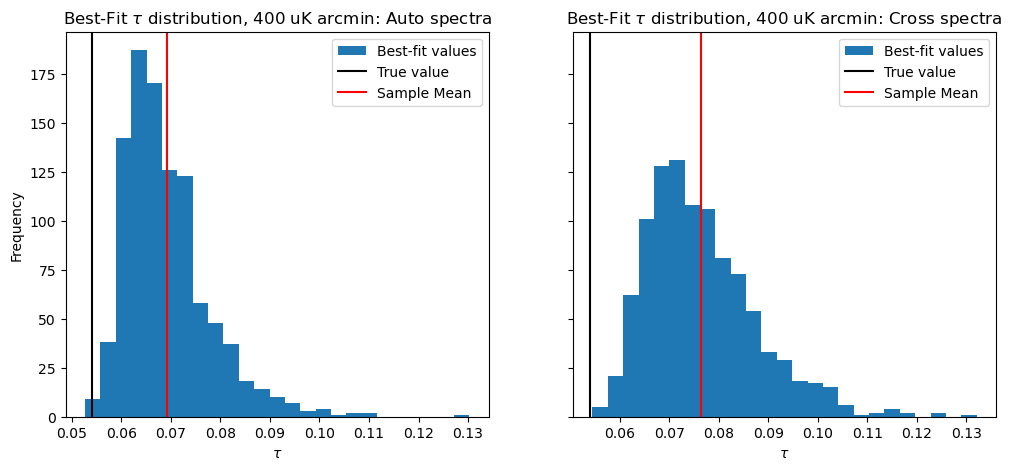

In [54]:
noise_400 = run_simulation(400,400,True, 1000)
noise_400_stats = get_simulation_stats(noise_400[0], noise_400[1], noise_400[2], noise_400[3])

auto = noise_400[0]
cross = noise_400[1]
print(f"{'Type':<28} {'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{'Auto Spectrum':<28} {auto.std():>12.6f} {auto.mean():>12.6f}")
print(f"{'Cross Spectrum':<28} {cross.std():>12.6f} {auto.mean():>12.6f}")

fig, ax = plt.subplots(1,2, figsize=(12,5), sharey=True)

ax[0].hist(auto, bins=25, density=False, label="Best-fit values")
ax[0].set_xlabel(r'$\tau$')
ax[0].set_ylabel("Frequency")
ax[0].set_title("Best-Fit "r'$\tau$' " distribution, 400 uK arcmin: Auto spectra")
ax[0].axvline(0.054, color='black', label="True value")
ax[0].axvline(auto.mean(), color='red', label="Sample Mean")
ax[0].legend(loc='best')

ax[1].hist(cross, bins=25, density=False, label="Best-fit values")
ax[1].set_xlabel(r'$\tau$')
ax[1].set_title("Best-Fit "r'$\tau$' " distribution, 400 uK arcmin: Cross spectra")
ax[1].axvline(0.054, color='black', label="True value")
ax[1].axvline(cross.mean(), color='red', label="Sample Mean")
ax[1].legend(loc='best')

done
Type                                  Std         Mean
------------------------------------------------------
Auto Spectrum                    0.016105     0.087043
Cross Spectrum                   0.014396     0.087043


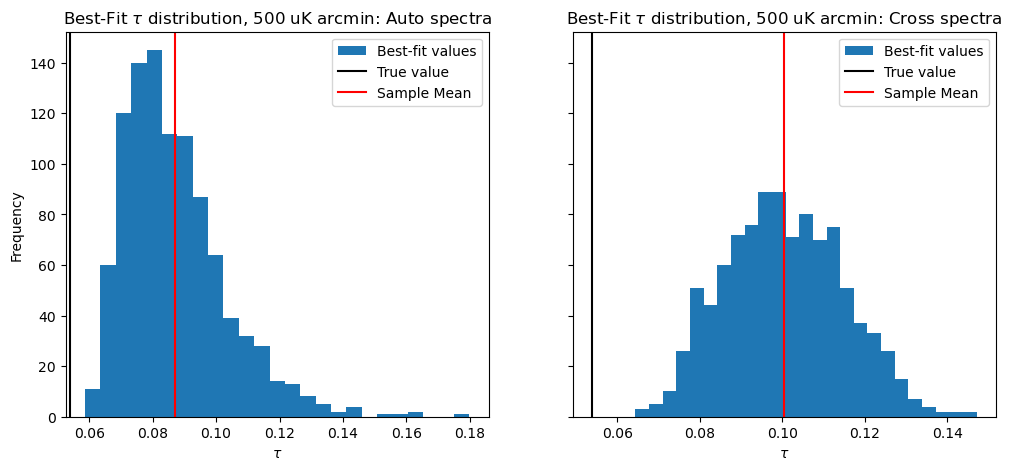

In [52]:
noise_500 = run_simulation(500,500,True, 1000)
noise_500_stats = get_simulation_stats(noise_500[0], noise_500[1], noise_500[2], noise_500[3])

auto = noise_500[0]
cross = noise_500[1]
print(f"{'Type':<28} {'Std':>12} {'Mean':>12}")
print("-" * 54)
print(f"{'Auto Spectrum':<28} {auto.std():>12.6f} {auto.mean():>12.6f}")
print(f"{'Cross Spectrum':<28} {cross.std():>12.6f} {auto.mean():>12.6f}")

fig, ax = plt.subplots(1,2, figsize=(12,5), sharey=True)

ax[0].hist(auto, bins=25, density=False, label="Best-fit values")
ax[0].set_xlabel(r'$\tau$')
ax[0].set_ylabel("Frequency")
ax[0].set_title("Best-Fit "r'$\tau$' " distribution, 500 uK arcmin: Auto spectra")
ax[0].axvline(0.054, color='black', label="True value")
ax[0].axvline(auto.mean(), color='red', label="Sample Mean")
ax[0].legend(loc='best')

ax[1].hist(cross, bins=25, density=False, label="Best-fit values")
ax[1].set_xlabel(r'$\tau$')
ax[1].set_title("Best-Fit "r'$\tau$' " distribution, 500 uK arcmin: Cross spectra")
ax[1].axvline(0.054, color='black', label="True value")
ax[1].axvline(cross.mean(), color='red', label="Sample Mean")
ax[1].legend(loc='best')

In [64]:
np.savez(
    "auto_tau.npz",
    noise_0=noise_0[0],
    noise_10=noise_10[0],
    noise_50=noise_50[0],
    noise_100=noise_100[0],
    noise_200=noise_200[0],
    noise_300=noise_300[0],
    noise_400=noise_400[0],
    noise_500=noise_500[0]
)
np.savez(
    "cross_tau.npz",
    noise_0=noise_0[0],
    noise_10=noise_10[1],
    noise_50=noise_50[1],
    noise_100=noise_100[1],
    noise_200=noise_200[1],
    noise_300=noise_300[1],
    noise_400=noise_400[1],
    noise_500=noise_500[1]
)
np.savez(
    "auto_ps.npz",
    noise_0=noise_0[1],
    noise_10=noise_10[2],
    noise_50=noise_50[2],
    noise_100=noise_100[2],
    noise_200=noise_200[2],
    noise_300=noise_300[2],
    noise_400=noise_400[2],
    noise_500=noise_500[2]
)
np.savez(
    "cross_ps.npz",
    noise_0=noise_0[1],
    noise_10=noise_10[3],
    noise_50=noise_50[3],
    noise_100=noise_100[3],
    noise_200=noise_200[3],
    noise_300=noise_300[3],
    noise_400=noise_400[3],
    noise_500=noise_500[3]
)



In [7]:
auto_tau = np.load("auto_tau.npz")
auto_tau_0 = auto_tau['noise_0']
auto_tau_10 = auto_tau['noise_10']
auto_tau_50 = auto_tau['noise_50']
auto_tau_100 = auto_tau['noise_100']
auto_tau_200 = auto_tau['noise_200']
auto_tau_300 = auto_tau['noise_300']
auto_tau_400 = auto_tau['noise_400']
auto_tau_500 = auto_tau['noise_500']

auto_ps = np.load("auto_ps.npz")
auto_ps_0 = auto_ps['noise_0']
auto_ps_10 = auto_ps['noise_10']
auto_ps_50 = auto_ps['noise_50']
auto_ps_100 = auto_ps['noise_100']
auto_ps_200 = auto_ps['noise_200']
auto_ps_300 = auto_ps['noise_300']
auto_ps_400 = auto_ps['noise_400']
auto_ps_500 = auto_ps['noise_500']

cross_tau = np.load("cross_tau.npz")
cross_tau_0 = cross_tau['noise_0']
cross_tau_10 = cross_tau['noise_10']
cross_tau_50 = cross_tau['noise_50']
cross_tau_100 = cross_tau['noise_100']
cross_tau_200 = cross_tau['noise_200']
cross_tau_300 = cross_tau['noise_300']
cross_tau_400 = cross_tau['noise_400']
cross_tau_500 = cross_tau['noise_500']

cross_ps = np.load("cross_ps.npz")
cross_ps_0 = cross_ps['noise_0']
cross_ps_10 = cross_ps['noise_10']
cross_ps_50 = cross_ps['noise_50']
cross_ps_100 = cross_ps['noise_100']
cross_ps_200 = cross_ps['noise_200']
cross_ps_300 = cross_ps['noise_300']
cross_ps_400 = cross_ps['noise_400']
cross_ps_500 = cross_ps['noise_500']

In [26]:
noise_0_stats = get_simulation_stats(auto_tau_0, cross_tau_0, auto_ps_0, cross_ps_0)
noise_10_stats = get_simulation_stats(auto_tau_10, cross_tau_10, auto_ps_10, cross_ps_10)
noise_50_stats = get_simulation_stats(auto_tau_50, cross_tau_50, auto_ps_50, cross_ps_50)
noise_100_stats = get_simulation_stats(auto_tau_100, cross_tau_100, auto_ps_100, cross_ps_100)
noise_200_stats = get_simulation_stats(auto_tau_200, cross_tau_200, auto_ps_200, cross_ps_200)
noise_300_stats = get_simulation_stats(auto_tau_300, cross_tau_300, auto_ps_300, cross_ps_300)
noise_400_stats = get_simulation_stats(auto_tau_400, cross_tau_400, auto_ps_400, cross_ps_400)
noise_500_stats = get_simulation_stats(auto_tau_500, cross_tau_500, auto_ps_500, cross_ps_500)

In [27]:
print(type(noise_0_stats[0]), noise_0_stats[0].shape)
print(type(noise_0_stats[2]), noise_0_stats[2].shape)
print(noise_0_stats[3][0][0])

<class 'numpy.float64'> ()
<class 'numpy.ndarray'> (2, 1, 31)
[3.09158988e-02 2.02384004e-02 9.95209676e-03 4.40574963e-03
 1.73814920e-03 7.17234248e-04 3.89931393e-04 2.42151867e-04
 1.77549271e-04 1.17752461e-04 9.73211978e-05 7.71855242e-05
 7.19760041e-05 6.60627947e-05 6.48976479e-05 6.62184367e-05
 7.04506494e-05 7.36135585e-05 8.08525055e-05 8.57246193e-05
 9.30379122e-05 9.83941832e-05 1.06647241e-04 1.10846010e-04
 1.16866463e-04 1.24812417e-04 1.29997030e-04 1.37050160e-04
 1.44471916e-04 1.53110633e-04 1.60153020e-04]


Text(0.5, 1.0, 'Noise Effects on Tau Uncertainty')

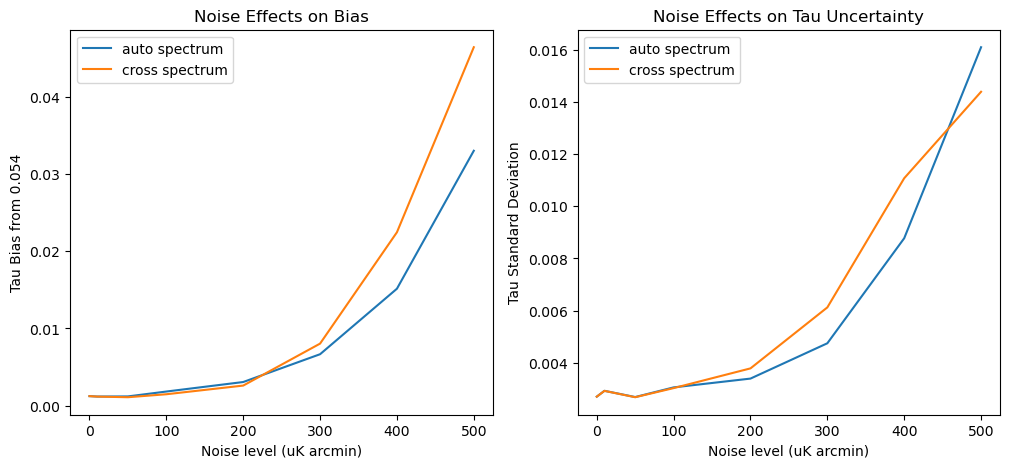

In [29]:
noise_levels = np.array([0,10,50,100,200,300,400,500])
bias_auto = np.array([noise_0_stats[0], noise_10_stats[0], noise_50_stats[0], noise_100_stats[0], noise_200_stats[0], noise_300_stats[0], noise_400_stats[0], noise_500_stats[0]])
err_auto = np.array([noise_0_stats[1], noise_10_stats[1], noise_50_stats[1], noise_100_stats[1], noise_200_stats[1], noise_300_stats[1], noise_400_stats[1], noise_500_stats[1]])
bias_cross = np.array([noise_0_stats[4], noise_10_stats[4], noise_50_stats[4], noise_100_stats[4], noise_200_stats[4], noise_300_stats[4], noise_400_stats[4], noise_500_stats[4]])
err_cross = np.array([noise_0_stats[5], noise_10_stats[5], noise_50_stats[5], noise_100_stats[5], noise_200_stats[5], noise_300_stats[5], noise_400_stats[5], noise_500_stats[5]])
fig, ax = plt.subplots(1,2, figsize=(12,5))
ax[0].plot(noise_levels, bias_auto, label="auto spectrum")
ax[0].plot(noise_levels, bias_cross, label="cross spectrum")
ax[0].legend()
ax[0].set_xlabel("Noise level (uK arcmin)")
ax[0].set_ylabel("Tau Bias from 0.054")
ax[0].set_title("Noise Effects on Bias")

ax[1].plot(noise_levels, err_auto, label='auto spectrum')
ax[1].plot(noise_levels, err_cross, label='cross spectrum')
ax[1].legend()
ax[1].set_xlabel("Noise level (uK arcmin)")
ax[1].set_ylabel("Tau Standard Deviation")
ax[1].set_title("Noise Effects on Tau Uncertainty")

In [64]:
NET = np.array([0,10,50,100,200,300,400,500])
T_per_pix = 365*24*60*60/npix
sigma_pix = NET/T_per_pix**0.5

Nl = 4*np.pi * sigma_pix**2 / npix
print(Nl)

[0.00000000e+00 3.98476998e-05 9.96192495e-04 3.98476998e-03
 1.59390799e-02 3.58629298e-02 6.37563197e-02 9.96192495e-02]


In [ ]:
ls = np.arange(2, lmax+1)
Z = ls*(ls+1)/(2*np.pi)

fig, ax = plt.subplots(1,2, figsize=(12,5))
ax[0].semilogx(ls, (noise_0_stats[2][0][0]-Nl[0])*Z, label='noiseless')
ax[0].semilogx(ls, (noise_10_stats[2][0][0]-Nl[1])*Z, label='10 uK arcmin')
ax[0].semilogx(ls, (noise_50_stats[2][0][0]-Nl[2])*Z, label='50 uK arcmin')
ax[0].semilogx(ls, (noise_100_stats[2][0][0]-Nl[3])*Z, label='100 uK arcmin')
ax[0].semilogx(ls, (noise_200_stats[2][0][0]-Nl[4])*Z, label='200 uK arcmin')
ax[0].semilogx(ls, (noise_300_stats[2][0][0]-Nl[5])*Z, label='300 uK arcmin')
ax[0].semilogx(ls, (noise_400_stats[2][0][0]-Nl[6])*Z, label='400 uK arcmin')
ax[0].semilogx(ls, (noise_500_stats[2][0][0]-Nl[7])*Z, label='500 uK arcmin')
ax[0].semilogx(ls, true_spectra[1][ls]*Z, label="true spectrum")
ax[0].set_xlabel(r'$\ell$')
ax[0].set_ylabel(r'$\frac{\ell(\ell+1)}{2\pi}C_\ell\mathrm{[\mu K^2]}$')
ax[0].legend(fontsize='small', loc='lower left')
ax[0].set_title("Mean auto spectra")

ax[1].semilogx(ls, (noise_0_stats[2][1][0]-Nl[0])*Z, label='noiseless')
ax[1].semilogx(ls, (noise_10_stats[2][1][0]-Nl[1])*Z, label='10 uK arcmin')
ax[1].semilogx(ls, (noise_50_stats[2][1][0]-Nl[2])*Z, label='50 uK arcmin')
ax[1].semilogx(ls, (noise_100_stats[2][1][0]-Nl[3])*Z, label='100 uK arcmin')
ax[1].semilogx(ls, (noise_200_stats[2][1][0]-Nl[4])*Z, label='200 uK arcmin')
ax[1].semilogx(ls, (noise_300_stats[2][1][0]-Nl[5])*Z, label='300 uK arcmin')
ax[1].semilogx(ls, (noise_400_stats[2][1][0]-Nl[6])*Z, label='400 uK arcmin')
ax[1].semilogx(ls, (noise_500_stats[2][1][0]-Nl[7])*Z, label='500 uK arcmin')
ax[1].set_xlabel(r'$\ell$')
ax[1].set_ylabel(r'$\frac{\ell(\ell+1)}{2\pi}C_\ell\mathrm{[\mu K^2]}$')
ax[1].legend(fontsize='small', loc='lower left')
ax[1].set_title("Standard deviation of auto spectra")

Text(0.5, 1.0, 'Standard deviation of auto spectra')

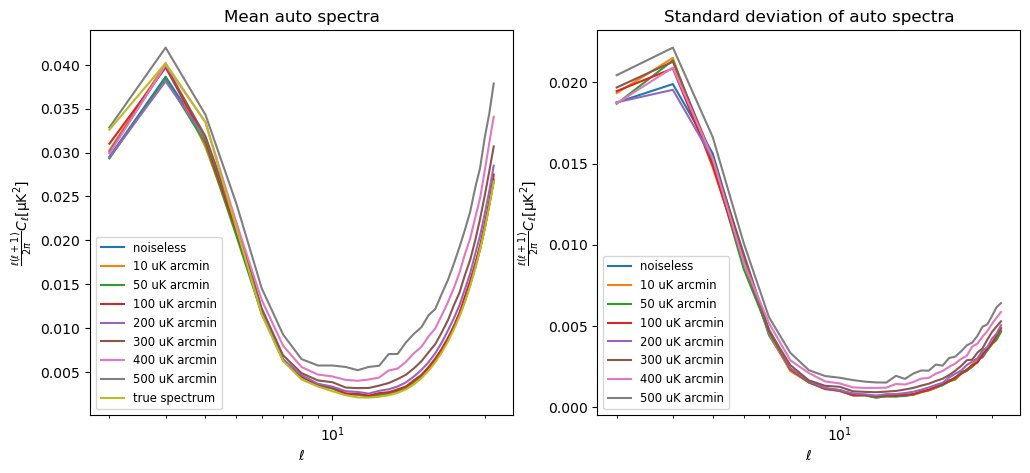

In [66]:
ls = np.arange(2, lmax+1)
Z = ls*(ls+1)/(2*np.pi)

fig, ax = plt.subplots(1,2, figsize=(12,5))
ax[0].semilogx(ls, noise_0_stats[2][0][0]*Z, label='noiseless')
ax[0].semilogx(ls, noise_10_stats[2][0][0]*Z, label='10 uK arcmin')
ax[0].semilogx(ls, noise_50_stats[2][0][0]*Z, label='50 uK arcmin')
ax[0].semilogx(ls, noise_100_stats[2][0][0]*Z, label='100 uK arcmin')
ax[0].semilogx(ls, noise_200_stats[2][0][0]*Z, label='200 uK arcmin')
ax[0].semilogx(ls, noise_300_stats[2][0][0]*Z, label='300 uK arcmin')
ax[0].semilogx(ls, noise_400_stats[2][0][0]*Z, label='400 uK arcmin')
ax[0].semilogx(ls, noise_500_stats[2][0][0]*Z, label='500 uK arcmin')
ax[0].semilogx(ls, true_spectra[1][ls]*Z, label="true spectrum")
ax[0].set_xlabel(r'$\ell$')
ax[0].set_ylabel(r'$\frac{\ell(\ell+1)}{2\pi}C_\ell\mathrm{[\mu K^2]}$')
ax[0].legend(fontsize='small', loc='lower left')
ax[0].set_title("Mean auto spectra")

ax[1].semilogx(ls, noise_0_stats[2][1][0]*Z, label='noiseless')
ax[1].semilogx(ls, noise_10_stats[2][1][0]*Z, label='10 uK arcmin')
ax[1].semilogx(ls, noise_50_stats[2][1][0]*Z, label='50 uK arcmin')
ax[1].semilogx(ls, noise_100_stats[2][1][0]*Z, label='100 uK arcmin')
ax[1].semilogx(ls, noise_200_stats[2][1][0]*Z, label='200 uK arcmin')
ax[1].semilogx(ls, noise_300_stats[2][1][0]*Z, label='300 uK arcmin')
ax[1].semilogx(ls, noise_400_stats[2][1][0]*Z, label='400 uK arcmin')
ax[1].semilogx(ls, noise_500_stats[2][1][0]*Z, label='500 uK arcmin')
ax[1].set_xlabel(r'$\ell$')
ax[1].set_ylabel(r'$\frac{\ell(\ell+1)}{2\pi}C_\ell\mathrm{[\mu K^2]}$')
ax[1].legend(fontsize='small', loc='lower left')
ax[1].set_title("Standard deviation of auto spectra")

Text(0.5, 1.0, 'Standard deviation of cross spectra')

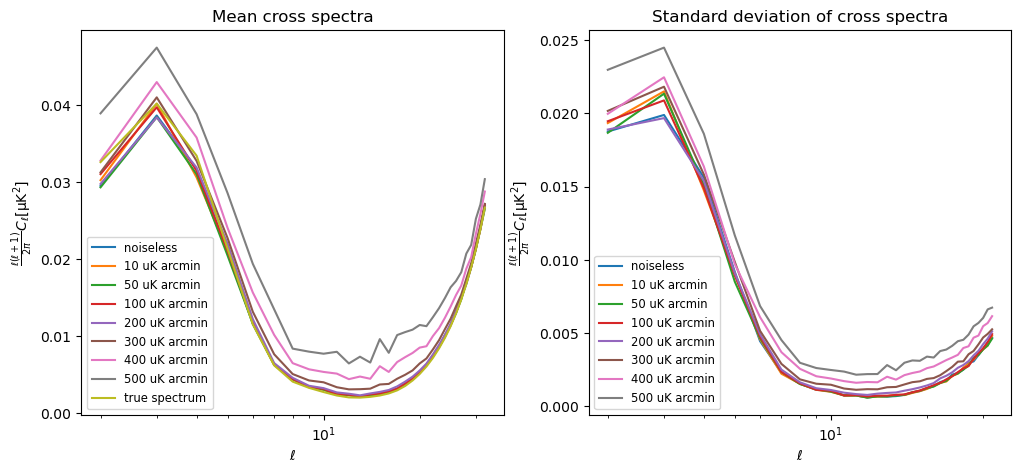

In [59]:
fig, ax = plt.subplots(1,2, figsize=(12,5))

ax[0].semilogx(ls, noise_0_stats[3][0][0]*Z, label='noiseless')
ax[0].semilogx(ls, noise_10_stats[3][0][0]*Z, label='10 uK arcmin')
ax[0].semilogx(ls, noise_50_stats[3][0][0]*Z, label='50 uK arcmin')
ax[0].semilogx(ls, noise_100_stats[3][0][0]*Z, label='100 uK arcmin')
ax[0].semilogx(ls, noise_200_stats[3][0][0]*Z, label='200 uK arcmin')
ax[0].semilogx(ls, noise_300_stats[3][0][0]*Z, label='300 uK arcmin')
ax[0].semilogx(ls, noise_400_stats[3][0][0]*Z, label='400 uK arcmin')
ax[0].semilogx(ls, noise_500_stats[3][0][0]*Z, label='500 uK arcmin')
ax[0].semilogx(ls, true_spectra[1][ls]*Z, label="true spectrum")
ax[0].set_xlabel(r'$\ell$')
ax[0].set_ylabel(r'$\frac{\ell(\ell+1)}{2\pi}C_\ell\mathrm{[\mu K^2]}$')
ax[0].legend(fontsize='small', loc='lower left')
ax[0].set_title("Mean cross spectra")

ax[1].semilogx(ls, noise_0_stats[3][1][0]*Z, label='noiseless')
ax[1].semilogx(ls, noise_10_stats[3][1][0]*Z, label='10 uK arcmin')
ax[1].semilogx(ls, noise_50_stats[3][1][0]*Z, label='50 uK arcmin')
ax[1].semilogx(ls, noise_100_stats[3][1][0]*Z, label='100 uK arcmin')
ax[1].semilogx(ls, noise_200_stats[3][1][0]*Z, label='200 uK arcmin')
ax[1].semilogx(ls, noise_300_stats[3][1][0]*Z, label='300 uK arcmin')
ax[1].semilogx(ls, noise_400_stats[3][1][0]*Z, label='400 uK arcmin')
ax[1].semilogx(ls, noise_500_stats[3][1][0]*Z, label='500 uK arcmin')
ax[1].set_xlabel(r'$\ell$')
ax[1].set_ylabel(r'$\frac{\ell(\ell+1)}{2\pi}C_\ell\mathrm{[\mu K^2]}$')
ax[1].legend(fontsize='small', loc='lower left')
ax[1].set_title("Standard deviation of cross spectra")

Text(0, 0.5, '$\\frac{\\ell(\\ell+1)}{2\\pi}C_\\ell\\mathrm{[\\mu K^2]}$')

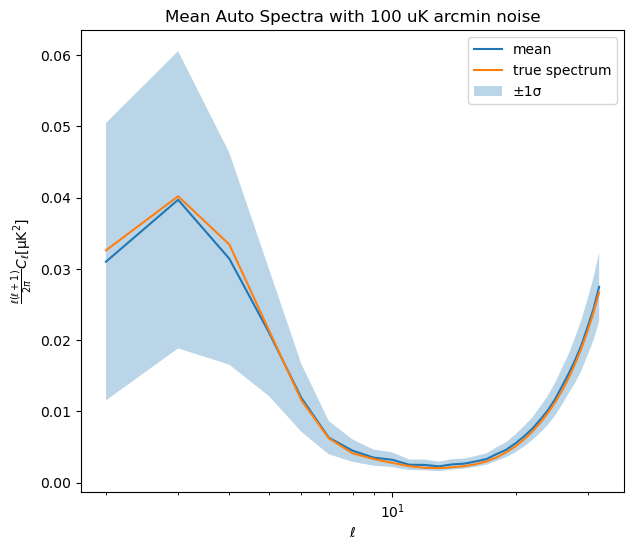

In [61]:
fig, ax=plt.subplots(figsize=(7,6))
ax.semilogx(ls, noise_100_stats[2][0][0]*Z, label='mean')
ax.semilogx(ls, true_spectra[1][ls]*Z, label="true spectrum")
ax.fill_between(
    ls,
    (noise_100_stats[2][0][0] - noise_100_stats[2][1][0])*Z,
    (noise_100_stats[2][0][0] + noise_100_stats[2][1][0])*Z,
    alpha=0.3,
    label="±1σ"
)
ax.legend()
ax.set_xlabel(r'$\ell$')
ax.set_title('Mean Auto Spectra with 100 uK arcmin noise')
ax.set_ylabel(r'$\frac{\ell(\ell+1)}{2\pi}C_\ell\mathrm{[\mu K^2]}$')

Text(0.5, 1.0, 'Mean Cross Spectra with 500 uK arcmin noise')

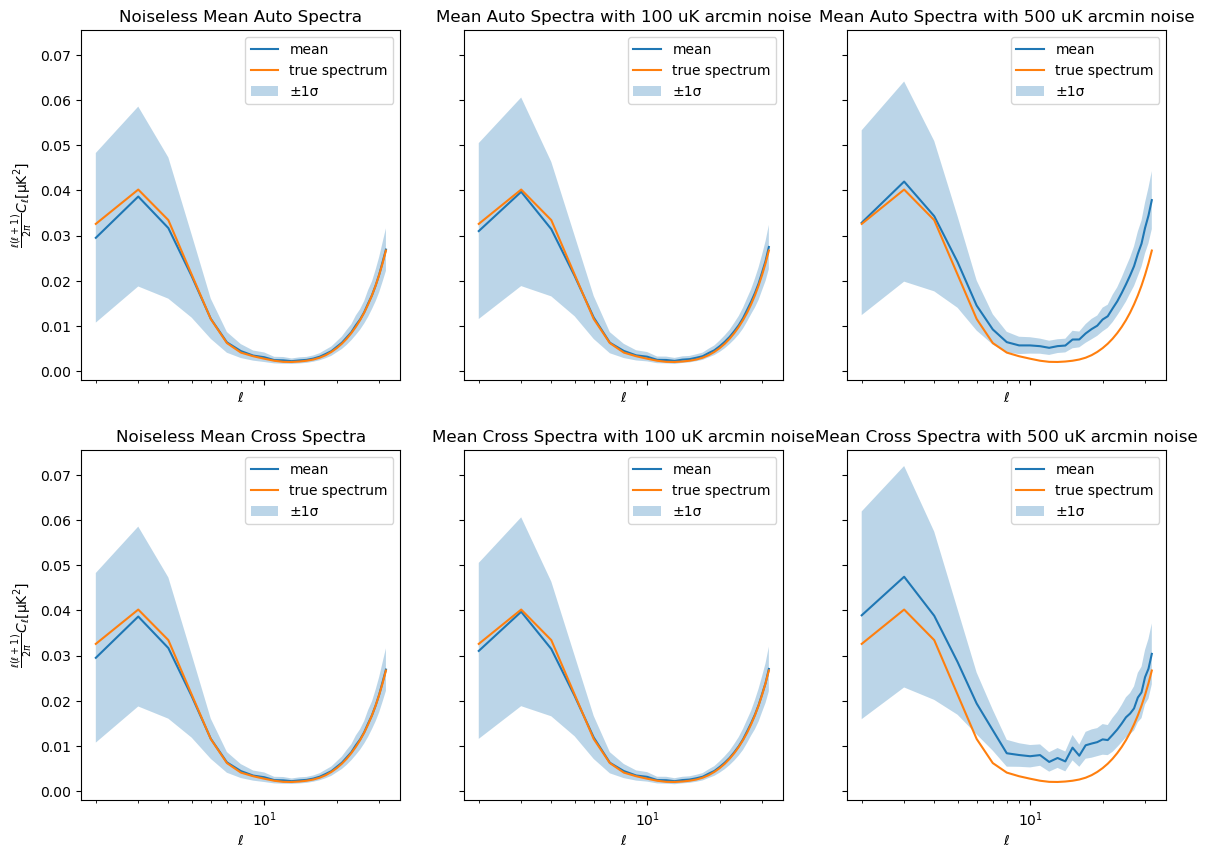

In [62]:
fig, ax = plt.subplots(2,3, figsize=(14,10), sharex=True, sharey=True)

ax[0][0].semilogx(ls, noise_0_stats[2][0][0]*Z, label='mean')
ax[0][0].semilogx(ls, true_spectra[1][ls]*Z, label="true spectrum")
ax[0][0].fill_between(
    ls,
    (noise_0_stats[2][0][0] - noise_0_stats[2][1][0])*Z,
    (noise_0_stats[2][0][0] + noise_0_stats[2][1][0])*Z,
    alpha=0.3,
    label="±1σ"
)
ax[0][0].legend()
ax[0][0].set_title('Noiseless Mean Auto Spectra')
ax[0][0].set_xlabel(r'$\ell$')
ax[0][0].set_ylabel(r'$\frac{\ell(\ell+1)}{2\pi}C_\ell\mathrm{[\mu K^2]}$')

ax[0][1].semilogx(ls, noise_100_stats[2][0][0]*Z, label='mean')
ax[0][1].semilogx(ls, true_spectra[1][ls]*Z, label="true spectrum")
ax[0][1].fill_between(
    ls,
    (noise_100_stats[2][0][0] - noise_100_stats[2][1][0])*Z,
    (noise_100_stats[2][0][0] + noise_100_stats[2][1][0])*Z,
    alpha=0.3,
    label="±1σ"
)
ax[0][1].legend()
ax[0][1].set_xlabel(r'$\ell$')
ax[0][1].set_title('Mean Auto Spectra with 100 uK arcmin noise')


ax[0][2].semilogx(ls, noise_500_stats[2][0][0]*Z, label='mean')
ax[0][2].semilogx(ls, true_spectra[1][ls]*Z, label="true spectrum")
ax[0][2].fill_between(
    ls,
    (noise_500_stats[2][0][0] - noise_500_stats[2][1][0])*Z,
    (noise_500_stats[2][0][0] + noise_500_stats[2][1][0])*Z,
    alpha=0.3,
    label="±1σ"
)
ax[0][2].legend()
ax[0][2].set_xlabel(r'$\ell$')
ax[0][2].set_title('Mean Auto Spectra with 500 uK arcmin noise')


ax[1][0].semilogx(ls, noise_0_stats[3][0][0]*Z, label='mean')
ax[1][0].semilogx(ls, true_spectra[1][ls]*Z, label="true spectrum")
ax[1][0].fill_between(
    ls,
    (noise_0_stats[3][0][0] - noise_0_stats[3][1][0])*Z,
    (noise_0_stats[3][0][0] + noise_0_stats[3][1][0])*Z,
    alpha=0.3,
    label="±1σ"
)
ax[1][0].legend()
ax[1][0].set_title('Noiseless Mean Cross Spectra')
ax[1][0].set_xlabel(r'$\ell$')
ax[1][0].set_ylabel(r'$\frac{\ell(\ell+1)}{2\pi}C_\ell\mathrm{[\mu K^2]}$')

ax[1][1].semilogx(ls, noise_100_stats[3][0][0]*Z, label='mean')
ax[1][1].semilogx(ls, true_spectra[1][ls]*Z, label="true spectrum")
ax[1][1].fill_between(
    ls,
    (noise_100_stats[3][0][0] - noise_100_stats[3][1][0])*Z,
    (noise_100_stats[3][0][0] + noise_100_stats[3][1][0])*Z,
    alpha=0.3,
    label="±1σ"
)
ax[1][1].legend()
ax[1][1].set_xlabel(r'$\ell$')
ax[1][1].set_title('Mean Cross Spectra with 100 uK arcmin noise')


ax[1][2].semilogx(ls, noise_500_stats[3][0][0]*Z, label='mean')
ax[1][2].semilogx(ls, true_spectra[1][ls]*Z, label="true spectrum")
ax[1][2].fill_between(
    ls,
    (noise_500_stats[3][0][0] - noise_500_stats[3][1][0])*Z,
    (noise_500_stats[3][0][0] + noise_500_stats[3][1][0])*Z,
    alpha=0.3,
    label="±1σ"
)
ax[1][2].legend()
ax[1][2].set_xlabel(r'$\ell$')
ax[1][2].set_title('Mean Cross Spectra with 500 uK arcmin noise')

## Noise Testing Part 2: cutsky

In [1]:
def cut_sky_wishart(noise, nsim, gal_deg, apodization_sigma, class_mask=False, verbose=True):
    tau_auto = []
    cls = []
    
    # NOISE CALCS
    npix = hp.nside2npix(nside)
    solid_angle = hp.nside2pixarea(nside)
    # map sensitivity
    sigma_pix = noise * (np.pi / 180 / 60)/ np.sqrt(solid_angle)
    
    Nl = 4*np.pi * sigma_pix**2 / npix

    # MASKS
    theta, phi = hp.pix2ang(nside, np.arange(hp.nside2npix(nside)))
    b = np.pi/2 - theta
    #gal_deg = 15
    mask_gal = np.abs(b) > np.deg2rad(gal_deg)

    mask_class = mt.dec_mask(nside, [-74, 28], coord='G') #dec range for CLASS map

    if class_mask:
        mask = mask_class & mask_gal
        if verbose:
            print(f"galactic mask of = {gal_deg:.3f} degrees and CLASS mask")
    else:
        mask = mask_gal
        if verbose:
            print(f"galactic mask of = {gal_deg:.3f} degrees")
    fsky = np.mean(mask)
    if verbose:
        print(f"fsky = {fsky:.3f}")
    bad_count = 0

    for i in range(nsim):
        s = hp.synfast(true_spectra, nside, lmax=lmax, new=True, pol=True)

        n1 = np.random.randn(npix) * sigma_pix 

        m_auto = (s + n1)

        Clhat_auto = np.array(polspice(m1=m_auto,weight1=mask, noT=True, pol=True, nlmax=lmax, apodizesigma=apodization_sigma)[1])

        x = ((Clhat_auto[ls][None, :])/(EE_grid[:, ls]+ Nl))

        # Diagnose problematic values
        if np.any(x <= 0):
            if verbose:
                print("WARNING: non-positive x")
                print("ell:", ls[np.any(x <= 0, axis=0)])
                print("Cl:", (Clhat_auto[ls][np.any(x <= 0, axis=0)]))
            bad_count += 1

        # Numerical protection
        x = np.maximum(x, 1e-10)

        chi2_auto = np.sum(
            (2*ls+1)*(x - np.log(x) - 1)*fsky,
            axis=1
        )

        tau_auto.append(tau_grid[np.argmin(chi2_auto)])
        cls.append(Clhat_auto)
    if verbose:
        print(f"Number of bad realizations: {bad_count}")
    return np.array(tau_auto), np.array(cls), bad_count

In [9]:
taus, cls, bad_count = cut_sky_wishart(20, 500, 20, 180, class_mask=False, verbose=True)

galactic mask of = 20.000 degrees
fsky = 0.656
ell: [8]
Cl: [-2.01266214e-05]
ell: [ 4 14]
Cl: [-1.72033498e-03 -1.48556029e-06]
ell: [8]
Cl: [-0.00010218]
ell: [9]
Cl: [-1.8620825e-05]
ell: [9]
Cl: [-2.38278611e-05]
ell: [7]
Cl: [-5.1960294e-05]
ell: [12]
Cl: [-3.99189085e-06]
ell: [8]
Cl: [-7.29477069e-06]
Number of bad realizations: 8


In [14]:
def get_simulation_stats(taus, cls):
    sigma_tau = np.std(taus)
    mean_tau = np.mean(taus)
    mean_cls = np.mean(cls, axis=0)
    std_cls = np.std(cls, axis=0)
    fractional_error_cls = np.full_like(mean_cls, np.nan, dtype=float)
    valid = mean_cls != 0
    fractional_error_cls[valid] = std_cls[valid] / mean_cls[valid]
    return mean_tau, sigma_tau, mean_cls, std_cls, fractional_error_cls

In [15]:
results = get_simulation_stats(taus, cls)

In [16]:
taus50, cls50, bad_count50 = cut_sky_wishart(50, 500, 20, 180, class_mask=False, verbose=True)

galactic mask of = 20.000 degrees
fsky = 0.656
ell: [8]
Cl: [-2.51620638e-05]
ell: [8]
Cl: [-5.87770447e-05]
Number of bad realizations: 2


In [17]:
results50 = get_simulation_stats(taus50, cls50)

In [18]:
taus100, cls100, bad_count100 = cut_sky_wishart(100, 500, 20, 180, class_mask=False, verbose=True)

galactic mask of = 20.000 degrees
fsky = 0.656
ell: [8]
Cl: [-6.18969928e-05]
Number of bad realizations: 1


In [19]:
results100 = get_simulation_stats(taus100, cls100)

In [20]:
taus_mask15, cls_mask15, bad_count_mask15 = cut_sky_wishart(20, 500, 15, 180, class_mask=False, verbose=True)
results_mask15 = get_simulation_stats(taus_mask15, cls_mask15)

galactic mask of = 15.000 degrees
fsky = 0.740
ell: [ 9 10]
Cl: [-1.83769346e-05 -2.19082766e-05]
ell: [8]
Cl: [-5.36483391e-06]
ell: [8]
Cl: [-8.43961512e-05]
Number of bad realizations: 3


In [21]:
taus50_mask15, cls50_mask15, bad_count50_mask15 = cut_sky_wishart(50, 500, 15, 180, class_mask=False, verbose=True)
results50_mask15 = get_simulation_stats(taus50_mask15, cls50_mask15)

galactic mask of = 15.000 degrees
fsky = 0.740
Number of bad realizations: 0


In [22]:
taus100_mask15, cls100_mask15, bad_count100_mask15 = cut_sky_wishart(100, 500, 15, 180, class_mask=False, verbose=True)
results100_mask15 = get_simulation_stats(taus100_mask15, cls100_mask15)

galactic mask of = 15.000 degrees
fsky = 0.740
Number of bad realizations: 0


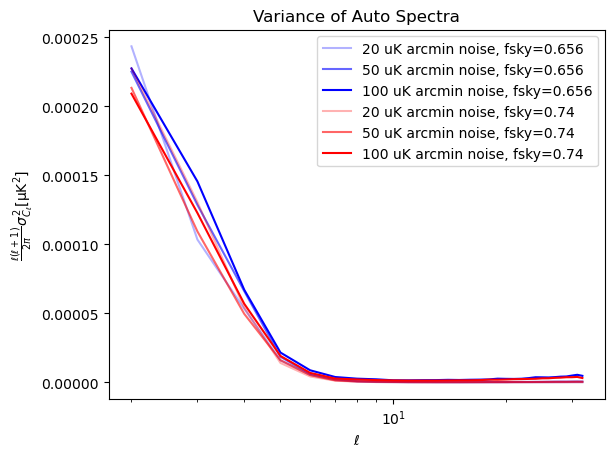

In [28]:
plt.semilogx(ls, (results[3][ls]**2)*Z, label='20 uK arcmin noise, fsky=0.656', color='blue', alpha=0.3)
plt.semilogx(ls, (results50[3][ls]**2)*Z, label='50 uK arcmin noise, fsky=0.656', color='blue', alpha=0.6)
plt.semilogx(ls, (results100[3][ls]**2)*Z, label='100 uK arcmin noise, fsky=0.656', color='blue', alpha=1)
plt.semilogx(ls, (results_mask15[3][ls]**2)*Z, label='20 uK arcmin noise, fsky=0.74', color='red', alpha=0.3)
plt.semilogx(ls, (results50_mask15[3][ls]**2)*Z, label='50 uK arcmin noise, fsky=0.74', color='red', alpha=0.6)
plt.semilogx(ls, (results100_mask15[3][ls]**2)*Z, label='100 uK arcmin noise, fsky=0.74', color='red', alpha=1)
plt.title("Variance of Auto Spectra")
plt.xlabel(r'$\ell$')
plt.ylabel(r'$\frac{\ell(\ell+1)}{2\pi}\sigma^2_{C_\ell}\mathrm{[\mu K^2]}$')
plt.legend()

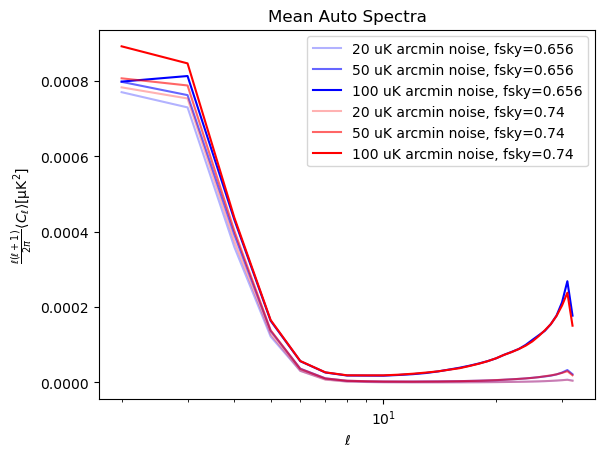

In [29]:
plt.semilogx(ls, (results[2][ls]**2)*Z, label='20 uK arcmin noise, fsky=0.656', color='blue', alpha=0.3)
plt.semilogx(ls, (results50[2][ls]**2)*Z, label='50 uK arcmin noise, fsky=0.656', color='blue', alpha=0.6)
plt.semilogx(ls, (results100[2][ls]**2)*Z, label='100 uK arcmin noise, fsky=0.656', color='blue', alpha=1)
plt.semilogx(ls, (results_mask15[2][ls]**2)*Z, label='20 uK arcmin noise, fsky=0.74', color='red', alpha=0.3)
plt.semilogx(ls, (results50_mask15[2][ls]**2)*Z, label='50 uK arcmin noise, fsky=0.74', color='red', alpha=0.6)
plt.semilogx(ls, (results100_mask15[2][ls]**2)*Z, label='100 uK arcmin noise, fsky=0.74', color='red', alpha=1)
plt.title("Mean Auto Spectra")
plt.xlabel(r'$\ell$')
plt.ylabel(r'$\frac{\ell(\ell+1)}{2\pi}\langle C_\ell \rangle\mathrm{[\mu K^2]}$')
plt.legend()

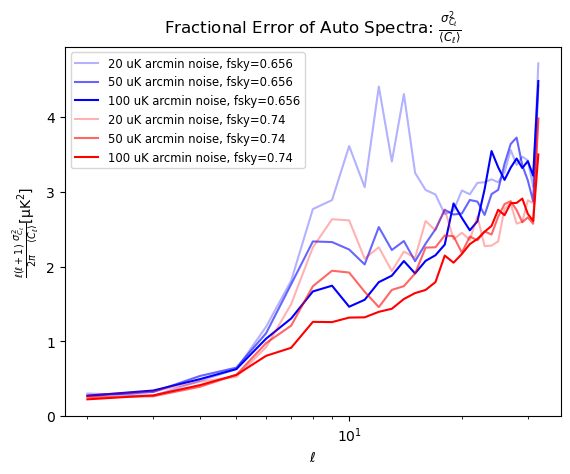

In [34]:
plt.semilogx(ls, (results[4][ls]**2)*Z, label='20 uK arcmin noise, fsky=0.656', color='blue', alpha=0.3)
plt.semilogx(ls, (results50[4][ls]**2)*Z, label='50 uK arcmin noise, fsky=0.656', color='blue', alpha=0.6)
plt.semilogx(ls, (results100[4][ls]**2)*Z, label='100 uK arcmin noise, fsky=0.656', color='blue', alpha=1)
plt.semilogx(ls, (results_mask15[4][ls]**2)*Z, label='20 uK arcmin noise, fsky=0.74', color='red', alpha=0.3)
plt.semilogx(ls, (results50_mask15[4][ls]**2)*Z, label='50 uK arcmin noise, fsky=0.74', color='red', alpha=0.6)
plt.semilogx(ls, (results100_mask15[4][ls]**2)*Z, label='100 uK arcmin noise, fsky=0.74', color='red', alpha=1)
plt.title(r"Fractional Error of Auto Spectra: $\frac{\sigma_{C_\ell}^2}{\langle C_\ell \rangle}$")
plt.xlabel(r'$\ell$')
plt.ylabel(r'$\frac{\ell(\ell+1)}{2\pi}\frac{\sigma_{C_\ell}^2}{\langle C_\ell \rangle}\mathrm{[\mu K^2]}$')
plt.legend(fontsize='small')

In [38]:
def cut_sky_wishart_2(noise, nsim, gal_deg, apodization_sigma, tau, class_mask=False, verbose=True):
    tau_auto = []
    cls = []
    spectra = get_Clhat(tau, lmax)
    
    # NOISE CALCS
    npix = hp.nside2npix(nside)
    solid_angle = hp.nside2pixarea(nside)
    # map sensitivity
    sigma_pix = noise * (np.pi / 180 / 60)/ np.sqrt(solid_angle)
    
    Nl = 4*np.pi * sigma_pix**2 / npix

    # MASKS
    theta, phi = hp.pix2ang(nside, np.arange(hp.nside2npix(nside)))
    b = np.pi/2 - theta
    #gal_deg = 15
    mask_gal = np.abs(b) > np.deg2rad(gal_deg)

    mask_class = mt.dec_mask(nside, [-74, 28], coord='G') #dec range for CLASS map

    if class_mask:
        mask = mask_class & mask_gal
        if verbose:
            print(f"galactic mask of = {gal_deg:.3f} degrees and CLASS mask")
    else:
        mask = mask_gal
        if verbose:
            print(f"galactic mask of = {gal_deg:.3f} degrees")
    fsky = np.mean(mask)
    if verbose:
        print(f"fsky = {fsky:.3f}")
    bad_count = 0

    for i in range(nsim):
        s = hp.synfast(spectra, nside, lmax=lmax, new=True, pol=True)

        n1 = np.random.randn(npix) * sigma_pix 

        m_auto = (s + n1)

        Clhat_auto = np.array(polspice(m1=m_auto,weight1=mask, noT=True, pol=True, nlmax=lmax, apodizesigma=apodization_sigma)[1])

        x = ((Clhat_auto[ls][None, :])/(EE_grid[:, ls]+ Nl))

        # Diagnose problematic values
        if np.any(x <= 0):
            if verbose:
                print("WARNING: non-positive x")
                print("ell:", ls[np.any(x <= 0, axis=0)])
                print("Cl:", (Clhat_auto[ls][np.any(x <= 0, axis=0)]))
            bad_count += 1

        # Numerical protection
        x = np.maximum(x, 1e-10)

        chi2_auto = np.sum(
            (2*ls+1)*(x - np.log(x) - 1)*fsky,
            axis=1
        )

        tau_auto.append(tau_grid[np.argmin(chi2_auto)])
        cls.append(Clhat_auto)
    if verbose:
        print(f"Number of bad realizations: {bad_count}")
    return np.array(tau_auto), np.array(cls), bad_count

In [39]:
def sigma_tau_plot_mask_2(noises, nsim, gal_deg, apodization_sigma, class_mask, tau):
    sigma_tau = []
    bias_tau = []
    bad_count = []

    for n in noises:
        auto, cls, bad = cut_sky_wishart_2(n, nsim, gal_deg, apodization_sigma, tau, class_mask, verbose=False)
        sigma_tau.append(auto.std())
        bias_tau.append(auto.mean() - tau)
        bad_count.append(bad)
        print(n)

    return np.array(sigma_tau), np.array(bias_tau), np.array(bad_count)

In [40]:
noises = np.arange(0,210,10)
sigma_tau4 = sigma_tau_plot_mask_2(noises, 200, 20, 180, False, 0.04)

0
10
20
30
40
50
60
70
80
90
100
110
120
130
140
150
160
170
180
190
200


In [41]:
import pandas as pd
goal = pd.read_csv("goal_table.csv", names=['noise','sigma_tau'])

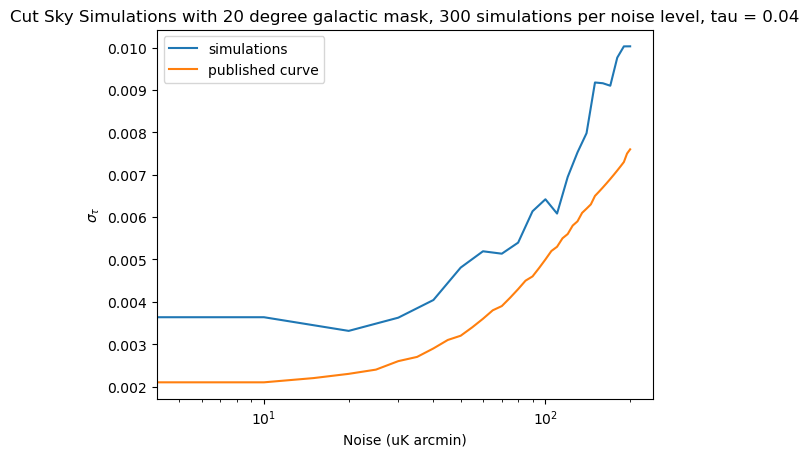

In [42]:
plt.semilogx(noises, sigma_tau4[0], label='simulations')
plt.semilogx(goal['noise'], goal['sigma_tau'], label='published curve')
plt.xlabel("Noise (uK arcmin)")
plt.ylabel(r'$\sigma_{\tau}$')
plt.title("Cut Sky Simulations with 20 degree galactic mask, 300 simulations per noise level, tau = 0.04")
plt.legend()

In [44]:
noises = np.arange(0,210,10)
sigma_tau6 = sigma_tau_plot_mask_2(noises, 200, 20, 180, False, 0.06)

0
10
20
30
40
50
60
70
80
90
100
110
120
130
140
150
160
170
180
190
200


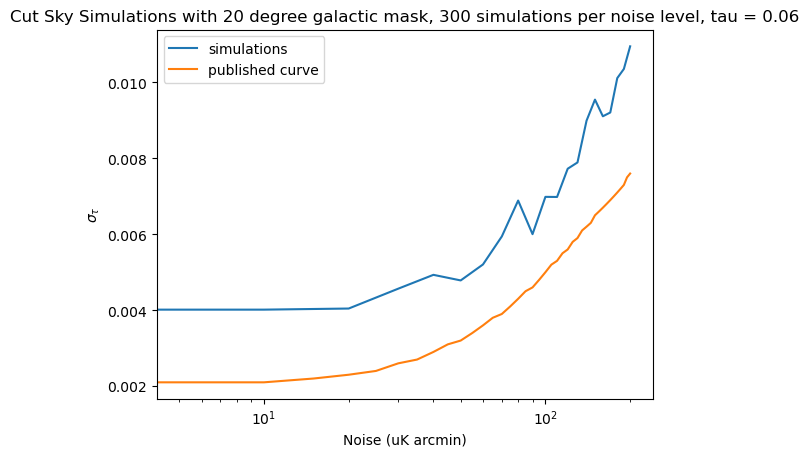

In [45]:
plt.semilogx(noises, sigma_tau6[0], label='simulations')
plt.semilogx(goal['noise'], goal['sigma_tau'], label='published curve')
plt.xlabel("Noise (uK arcmin)")
plt.ylabel(r'$\sigma_{\tau}$')
plt.title("Cut Sky Simulations with 20 degree galactic mask, 300 simulations per noise level, tau = 0.06")
plt.legend()

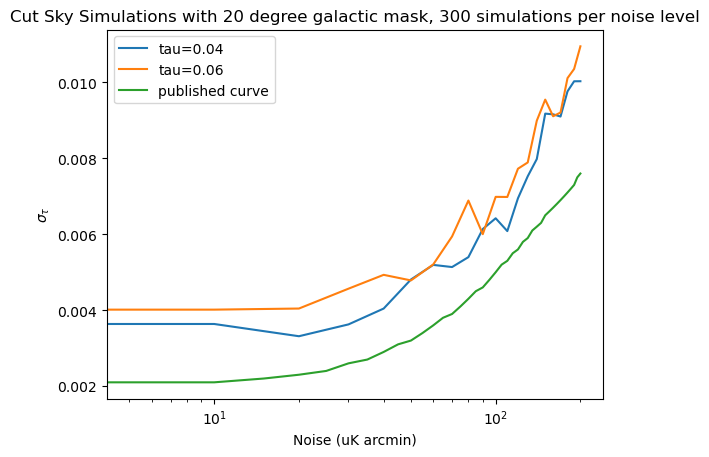

In [47]:
plt.semilogx(noises, sigma_tau4[0], label='tau=0.04')
plt.semilogx(noises, sigma_tau6[0], label='tau=0.06')
plt.semilogx(goal['noise'], goal['sigma_tau'], label='published curve')
plt.xlabel("Noise (uK arcmin)")
plt.ylabel(r'$\sigma_{\tau}$')
plt.title("Cut Sky Simulations with 20 degree galactic mask, 300 simulations per noise level")
plt.legend()